# ETL y análisis exploratorio de datos del TFM
**Predicción del flujo turístico en Mallorca mediante modelos de inteligencia artificial y variables externas**

Este notebook documenta y ejecuta la extracción, limpieza e integración de las fuentes del proyecto. Los Excel originales permanecen intactos. Cada ejecución genera el dataset maestro y evidencias de calidad en `outputs/etl/`.

## 1. Alcance y decisiones metodológicas
La variable objetivo es el número mensual de turistas cuyo destino principal es Mallorca, para el agregado de residencia «Mundo (excluida Illes Balears)». No se suman países y agregados porque se solapan. El periodo de estudio es octubre de 2015–diciembre de 2025: 123 meses antes de crear retardos. Los datos anteriores a 2025 se destinan al entrenamiento y validación temporal; 2025 se reserva para la evaluación final.

Las variables externas candidatas incluyen cuatro índices de Google Trends, además de pasajeros y operaciones del aeropuerto de Palma, viajeros hoteleros, pernoctaciones, estancia media y ocupación. Las estadísticas aeroportuarias incluyen llegadas y salidas; los viajeros de hoteles y los turistas de FRONTUR son poblaciones distintas. No se interpretan como medidas equivalentes ni como relaciones causales.

AEMET está pendiente de acceso. No se fabrican columnas meteorológicas ni se sustituyen por ceros. La integración meteorológica será una ampliación del ETL.

## 2. Reproducción
Desde la raíz del repositorio: `python -m pip install -r requirements.txt` y `jupyter lab`. Abrir este notebook y ejecutar **Restart Kernel and Run All Cells**. Requiere las carpetas originales `Datasets/Tráfico aéreo`, `Datasets/Alojamiento` , `Datasets/Google Trends` y `Datasets/Dataset Principal.xlsx`. Las rutas son relativas al proyecto. No requiere red ni claves de API para procesar las descargas actuales.

El resultado se guarda al final, únicamente si pasan las comprobaciones estructurales. Los ausentes documentados no impiden exportar; permanecen identificados para decidir su tratamiento en la fase de modelización.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import re
import unicodedata
import pandas as pd
from openpyxl import load_workbook
import xlrd

# Si se ejecuta desde otra carpeta, indicar aquí la raíz del repositorio.
PROJECT_ROOT = Path.cwd()
assert (PROJECT_ROOT / "Datasets").is_dir(), "Ejecutar desde la raíz del repositorio."
DATA_ROOT = PROJECT_ROOT / "Datasets"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "etl"
START, END = "2015-10-01", "2025-12-01"
EXPECTED = pd.date_range(START, END, freq="MS")
AIR_EXPECTED = pd.date_range("2015-01-01", END, freq="MS")
versions = {p: importlib.metadata.version(p) for p in ["pandas", "openpyxl", "xlrd"]}
print("Python:", platform.python_version(), "Dependencias:", versions)
print("Periodo:", EXPECTED.min().date(), "a", EXPECTED.max().date(), "Meses:", len(EXPECTED))

Python: 3.11.9 Dependencias: {'pandas': '3.0.3', 'openpyxl': '3.1.5', 'xlrd': '2.0.2'}
Periodo: 2015-10-01 a 2025-12-01 Meses: 123


## 3. Fuentes y trazabilidad
| Fuente | Archivo o carpeta | Selección | Unidad |
|---|---|---|---|
| IBESTAT / FRONTUR | Dataset Principal.xlsx | Mallorca, TURISTAS, 5000_XIB | Personas |
| AENA | Tráfico aéreo / año / informe mensual | PALMA DE MALLORCA, pasajeros y operaciones | Movimientos de pasajeros / aterrizajes y despegues |
| IBESTAT / ocupación hotelera | Alojamiento / Grado de ocupación… | Mallorca, categoría HOTEL | Porcentaje |
| IBESTAT / demanda hotelera | Alojamiento / Viajeros entrados… | Mallorca, residencia _T (Total) | Viajeros / noches / noches por viajero |

Fuentes de descarga: [AENA](https://www.aena.es/es/estadisticas/informes-mensuales.html), [IBESTAT](https://ibestat.es/edatos/apps/catalogo/es/dataset/?groups=turismo) y [AEMET OpenData, pendiente](https://opendata.aemet.es/centrodedescargas/productosAEMET).

Se registra una huella SHA-256 por archivo para identificar exactamente las descargas empleadas. La huella no acredita la exactitud estadística; permite detectar cambios en los archivos. La fecha de descarga no se conoce y no se inventa.

In [2]:
tourism_path = DATA_ROOT / "Dataset Principal.xlsx"
occupancy_path = DATA_ROOT / "Alojamiento" / "Grado de ocupación hotelera por categoría, isla y mes.xlsx"
hotel_path = DATA_ROOT / "Alojamiento" / "Viajeros entrados, pernoctaciones y estancia media en establecimientos hoteleros.xlsx"
air_paths = sorted((DATA_ROOT / "Tráfico aéreo").rglob("*.xls*"))
GT_SPECS = {
    "Mallorca-Alemania.csv": ("gt_mallorca_alemania", "Mallorca", "Alemania"),
    "Majorca-Alemania.csv": ("gt_majorca_alemania", "Majorca", "Alemania"),
    "Mallorca-Reino Unido.csv": ("gt_mallorca_reino_unido", "Mallorca", "Reino Unido"),
    "Majorca-Reino Unido.csv": ("gt_majorca_reino_unido", "Majorca", "Reino Unido"),
}
gt_paths = [DATA_ROOT / "Google Trends" / name for name in GT_SPECS]
source_paths = [tourism_path, occupancy_path, hotel_path, *air_paths, *gt_paths]
assert air_paths, "No se encontraron informes AENA."
assert all(p.is_file() for p in source_paths), "Falta una fuente requerida."
manifest = pd.DataFrame([{
    "archivo": p.relative_to(PROJECT_ROOT).as_posix(),
    "bytes": p.stat().st_size,
    "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
} for p in source_paths])
print("Archivos incluidos:", len(manifest), "Informes AENA:", len(air_paths))
display(manifest.head())

Archivos incluidos: 139 Informes AENA: 132


,archivo,bytes,sha256
0,Datasets/Dataset Principal.xlsx,1037932,8a18c2790a0c0d0b496ab62c092ac745ae06e9f3e43318...
1,Datasets/Alojamiento/Grado de ocupación hotele...,2672908,866acd274fce591e3bf4bde3f257aa1d770b6099b88266...
2,"Datasets/Alojamiento/Viajeros entrados, pernoc...",23509480,72642b8433108c8e0aea303f2e6d58108b401ce365ae29...
3,Datasets/Tráfico aéreo/2015/01.Enero-Definitiv...,45568,3d0914977fe6558e36a6419f0a823ca9ad706d58f227b1...
4,Datasets/Tráfico aéreo/2015/02.Febrero-Definit...,59392,d3b751957fffb7717a7ef2e3fff540abcd565fc76fbee8...


## 4. Reglas comunes de limpieza
Se seleccionan los periodos con código `AAAA-Mmm`; las filas anuales se excluyen. Cada tabla filtrada debe tener una sola fila por mes. Las conversiones numéricas rechazan textos inesperados, en lugar de ocultarlos como ausentes. Los vacíos permanecen como valores ausentes; un cero numérico permanece como cero.

Se conservan los estados de observación de la fuente: `A` = valor normal, `P` = valor provisional, `U` = baja fiabilidad y `O` = valor no disponible. Un valor ausente y su estado se revisan por separado. El ETL no interpola, no normaliza, no elimina la pandemia y no calcula medias con el conjunto de evaluación.

In [3]:
def number(values):
    clean = values.replace(r"^\s*$", pd.NA, regex=True)
    return pd.to_numeric(clean, errors="raise")

def select_monthly(frame, filters):
    required = {"TIME_PERIOD_CODE", "OBS_VALUE", "ESTADO_OBSERVACION_CODE", *filters}
    assert required <= set(frame.columns), f"Faltan columnas: {required - set(frame.columns)}"
    mask = frame["TIME_PERIOD_CODE"].astype(str).str.fullmatch(r"\d{4}-M\d{2}")
    for column, value in filters.items():
        mask &= frame[column].eq(value)
    selected = frame.loc[mask].copy()
    assert not selected.empty, f"Selección vacía: {filters}"
    selected["fecha"] = pd.to_datetime(selected["TIME_PERIOD_CODE"].str.replace("-M", "-", regex=False), format="%Y-%m")
    selected["valor"] = number(selected["OBS_VALUE"])
    assert not selected["fecha"].duplicated().any(), f"Meses duplicados: {filters}"
    return selected.sort_values("fecha").set_index("fecha")

def source_series(selected, name):
    return selected[["valor", "ESTADO_OBSERVACION_CODE"]].rename(columns={
        "valor": name, "ESTADO_OBSERVACION_CODE": name + "_estado"
    })

## 5. Extracción de la variable objetivo
Se utiliza el agregado total disponible de Mallorca. Las tasas de variación se excluyen: no son recuentos de turistas y su importación presenta problemas de escala. Los valores provisionales y los ceros de baja fiabilidad se conservan con su estado. La evaluación posterior deberá explicar esta limitación de calidad y el uso de una descarga revisada, no de las versiones históricas disponibles en cada fecha.

In [4]:
tourism_raw = pd.read_excel(tourism_path, sheet_name=0, engine="openpyxl")
tourism_selected = select_monthly(tourism_raw, {
    "TERRITORIO_CODE": "ES532", "MEDIDAS_CODE": "TURISTAS", "LUGAR_RESIDENCIA_CODE": "5000_XIB"
})
tourism = source_series(tourism_selected, "turistas")
assert tourism.reindex(EXPECTED)["turistas"].notna().all(), "Faltan turistas en el periodo de estudio."
print("Histórico objetivo:", tourism.index.min().date(), "a", tourism.index.max().date())
display(tourism.loc[START:END].head())

Histórico objetivo: 2015-10-01 a 2026-08-01


,turistas,turistas_estado
fecha,,
2015-10-01,872479.0,A
2015-11-01,172354.0,A
2015-12-01,129772.0,A
2016-01-01,150340.0,A
2016-02-01,220405.0,A


## 6. Extracción de AENA y revisión de formatos
Los informes antiguos son `.xls` y los recientes `.xlsx`. Las hojas y las columnas cambian entre años. Se ignoran las hojas técnicas «Mozart Reports», se identifica la hoja estadística y se comprueba el mes y año de su cabecera frente al nombre del archivo. Se detiene la lectura antes del bloque acumulado, cuando aparece.

Los tres bloques horizontales corresponden a pasajeros, operaciones y mercancías. Se localiza Palma en cada bloque y se toma el primer número a su derecha, admitiendo las columnas vacías de las versiones antiguas. Se comprueban los rótulos y el orden de los bloques; se excluyen mercancías y porcentajes de variación. Se registra archivo, hoja y posición de cada cifra extraída. Cualquier formato inesperado detiene la ejecución.

In [5]:
def norm(value):
    text = unicodedata.normalize("NFKD", str(value))
    return "".join(c for c in text if not unicodedata.combining(c)).upper().strip()

MONTH_NAMES = ["ENERO", "FEBRERO", "MARZO", "ABRIL", "MAYO", "JUNIO", "JULIO", "AGOSTO", "SEPTIEMBRE", "OCTUBRE", "NOVIEMBRE", "DICIEMBRE"]

def air_sheets(path):
    if path.suffix.lower() == ".xls":
        book = xlrd.open_workbook(path)
        return [(s.name, [s.row_values(i) for i in range(s.nrows)]) for s in book.sheets()
                if s.name != "Mozart Reports" and "ACUMUL" not in norm(s.name)]
    book = load_workbook(path, read_only=True, data_only=True)
    try:
        return [(s.title, list(s.values)) for s in book
                if s.title != "Mozart Reports" and "ACUMUL" not in norm(s.title)]
    finally:
        book.close()

def extract_air(path):
    year = int(path.parent.name)
    month = int(re.match(r"\d+", path.name).group())
    assert 1 <= month <= 12
    candidates = []
    for name, rows in air_sheets(path):
        header = " ".join(norm(v) for row in rows[:10] for v in row if v is not None)
        if "ACUMULADO" in header:
            continue
        if "PASAJEROS" not in header or "OPERACIONES" not in header:
            continue
        assert str(year) in header and MONTH_NAMES[month - 1] in header, f"Cabecera/archivo no coinciden: {path.name}"
        block_positions = {}
        for row in rows[:12]:
            for column, value in enumerate(row):
                for block in ["PASAJEROS", "OPERACIONES", "MERCANC"]:
                    if norm(value).startswith(block):
                        block_positions.setdefault(block, column)
        assert len(block_positions) == 3, f"Bloques desconocidos: {path.name}"
        assert block_positions["PASAJEROS"] < block_positions["OPERACIONES"] < block_positions["MERCANC"]
        hits = []
        for i, row in enumerate(rows):
            if any("ACUMULADO" in norm(v) for v in row if v is not None):
                break
            for j, value in enumerate(row):
                if norm(value) == "PALMA DE MALLORCA":
                    numbers = [(j+k+1, v) for k, v in enumerate(row[j+1:j+4])
                               if isinstance(v, (int, float)) and not isinstance(v, bool)]
                    assert numbers, f"Sin cifra de Palma: {path.name}"
                    c, amount = numbers[0]
                    assert amount >= 0 and float(amount).is_integer(), f"Recuento inválido: {path.name}"
                    hits.append((j, i, c, int(amount)))
        hits.sort()
        assert len(hits) == 3 and len({h[0] for h in hits}) == 3, f"Bloques Palma ambiguos: {path.name}"
        # Primera columna de aeropuertos: pasajeros; segunda: operaciones.
        candidates.append({"fecha": pd.Timestamp(year, month, 1), "pasajeros_aena": hits[0][3],
                           "operaciones_aena": hits[1][3], "archivo_aena": path.relative_to(PROJECT_ROOT).as_posix(),
                           "hoja_aena": name, "fila_pasajeros": hits[0][1]+1, "columna_pasajeros": hits[0][2]+1,
                           "fila_operaciones": hits[1][1]+1, "columna_operaciones": hits[1][2]+1,
                           "estado_cabecera": "provisional" if "PROVISIONAL" in header else "definitivo" if "DEFINITIV" in header else "no identificado"})
    assert len(candidates) == 1, f"Hoja mensual ambigua/ausente: {path.name}"
    return candidates[0]

air_audit = pd.DataFrame([extract_air(path) for path in air_paths]).sort_values("fecha")
assert not air_audit["fecha"].duplicated().any(), "Informes mensuales duplicados."
assert set(air_audit["fecha"]) == set(AIR_EXPECTED), "Faltan o sobran meses AENA 2015–2025."
air = air_audit.set_index("fecha")[["pasajeros_aena", "operaciones_aena", "estado_cabecera"]].rename(columns={"estado_cabecera":"aena_estado"})
print("Informes mensuales comprobados:", len(air))
display(air_audit.loc[air_audit["fecha"].dt.month.eq(1), ["fecha", "pasajeros_aena", "operaciones_aena", "hoja_aena"]])

Informes mensuales comprobados: 132


,fecha,pasajeros_aena,operaciones_aena,hoja_aena
0,2015-01-01,565027,5952,ENERO
12,2016-01-01,613548,6509,ENERO 2016
24,2017-01-01,642413,6931,ENERO 2017
36,2018-01-01,704996,7047,ENERO 2018
48,2019-01-01,839130,8468,ENERO 2019
60,2020-01-01,820661,7660,ENERO 2020
72,2021-01-01,165533,3333,ENERO 2021
84,2022-01-01,559675,6941,ENERO 2022
96,2023-01-01,858580,8356,ENERO 2023
108,2024-01-01,889815,8650,Ranking mensual (con 2019)


## 7. Actividad hotelera y comprobación de decimales
La ocupación se selecciona para Mallorca y la categoría agregada `HOTEL`; los porcentajes no se suman entre categorías. Viajeros y pernoctaciones se seleccionan para Mallorca y residencia `_T` (Total), sin volver a sumar países.

La estancia media importada debe verificarse contra `pernoctaciones / viajeros`. Para cada mes con denominador positivo se contrasta tanto el valor original como el valor dividido entre 100. Solo se corrige cuando la segunda interpretación coincide con el cociente dentro de 0,015 noches, tolerancia para el redondeo de la estadística a dos decimales. No se aplica una división indiscriminada. Los casos sin referencia verificable permanecen ausentes y los casos incompatibles detienen la ejecución. Se conserva el valor original y se exporta la decisión de cada fila.

In [6]:
occupancy_raw = pd.read_excel(occupancy_path, sheet_name=0, engine="openpyxl")
occupancy_measures = {
    "GRADO_OCUPACION_HABITACION_TURISTICA": "ocupacion_habitaciones_pct",
    "GRADO_OCUPACION_PLAZA_TURISTICA": "ocupacion_plazas_pct",
    "GRADO_OCUPACION_PLAZA_TURISTICA_FIN_SEMANA": "ocupacion_fin_semana_pct",
}
occupancy_parts = []
for measure, name in occupancy_measures.items():
    selected = select_monthly(occupancy_raw, {"TERRITORIO_CODE":"ES532", "ALOJAMIENTOS_TURISTICOS_CODE":"HOTEL", "MEDIDAS_CODE":measure})
    assert selected["valor"].dropna().between(0, 100).all(), f"Ocupación fuera de rango: {name}"
    occupancy_parts.append(source_series(selected, name))
occupancy = pd.concat(occupancy_parts, axis=1)

hotel_raw = pd.read_excel(hotel_path, sheet_name=0, engine="openpyxl")
hotel_measures = {"VIAJEROS":"viajeros_hoteles", "PERNOCTACION_TURISTICA":"pernoctaciones_hoteles", "ESTANCIA_MEDIA":"estancia_media_original"}
hotel_parts = []
for measure, name in hotel_measures.items():
    selected = select_monthly(hotel_raw, {"TERRITORIO_CODE":"ES532", "LUGAR_RESIDENCIA_CODE":"_T", "MEDIDAS_CODE":measure})
    hotel_parts.append(source_series(selected, name))
hotel = pd.concat(hotel_parts, axis=1)
ratio = hotel["pernoctaciones_hoteles"].div(hotel["viajeros_hoteles"].where(hotel["viajeros_hoteles"] > 0))
original = hotel["estancia_media_original"]
direct = original.sub(ratio).abs().le(0.015)
scaled = original.div(100).sub(ratio).abs().le(0.015) & ~direct
verifiable = original.notna() & ratio.notna()
assert (direct | scaled | ~verifiable).all(), "Hay estancias medias incompatibles: revisar la fuente."
hotel["estancia_media_noches"] = original.where(direct).combine_first(original.div(100).where(scaled))
hotel["estancia_media_noches_estado"] = hotel["estancia_media_original_estado"]
hotel["estancia_media_ajuste"] = "sin referencia o valor ausente"
hotel.loc[direct, "estancia_media_ajuste"] = "original verificado"
hotel.loc[scaled, "estancia_media_ajuste"] = "división entre 100 verificada"
decimal_audit = hotel[["viajeros_hoteles", "pernoctaciones_hoteles", "estancia_media_original", "estancia_media_noches", "estancia_media_ajuste"]].assign(cociente=ratio)
print("Correcciones de escala en el periodo de estudio:", int(scaled.reindex(EXPECTED, fill_value=False).sum()))
display(decimal_audit.loc[START:END].head())

C:\Users\acort\AppData\Roaming\Python\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Correcciones de escala en el periodo de estudio: 121


,viajeros_hoteles,pernoctaciones_hoteles,estancia_media_original,estancia_media_noches,estancia_media_ajuste,cociente
fecha,,,,,,
2015-10-01,669333.0,4451098.0,665.0,6.65,división entre 100 verificada,6.650050
2015-11-01,70782.0,296567.0,419.0,4.19,división entre 100 verificada,4.189865
2015-12-01,48185.0,177795.0,369.0,3.69,división entre 100 verificada,3.689841
2016-01-01,47222.0,204917.0,434.0,4.34,división entre 100 verificada,4.339439
2016-02-01,109993.0,504874.0,459.0,4.59,división entre 100 verificada,4.590056


## 7 bis. Google Trends: extracción de los CSV

Se incorporan cuatro consultas: «Mallorca» y «Majorca», cada una en Alemania y Reino Unido. El país representa el origen de la búsqueda. La cabecera acredita la categoría **Viajes**, el término y el país; no acredita la fecha de descarga, el tipo de búsqueda ni la URL original. Esos campos se registran como desconocidos, sin convertir las instrucciones de descarga en hechos comprobados.

Cada CSV contiene dos líneas de preámbulo y una tabla mensual. Se verifica la cabecera, la frecuencia, los duplicados y el intervalo 0–100. Se preservan ceros y ausentes. Un cero de Google Trends puede representar volumen insuficiente; no significa necesariamente ausencia de búsquedas. Un valor «<1», si aparece, se guarda como ausente y se marca para decidir su tratamiento posteriormente, sin asignarle un número arbitrario.

Los índices son relativos y se han descargado por separado: no se suman ni se interpretan como cantidades de búsquedas o cuotas comparables entre países. Los meses de enero a septiembre de 2015 permanecen en la extracción auxiliar para posibles retardos; el calendario maestro sigue comenzando en octubre. La vista general de disponibilidad utiliza el calendario del maestro y pierde el contexto anterior en sus filas iniciales.

Fuente metodológica: [documentación de Google sobre muestreo y normalización](https://support.google.com/trends/answer/4365533?hl=es). Las comprobaciones del bloque son estructurales; no seleccionan variables para los modelos.

In [7]:
GT_COLUMNS = [spec[0] for spec in GT_SPECS.values()]
gt_parts, gt_records = [], []
for filename, (column, term, country) in GT_SPECS.items():
    path = DATA_ROOT / "Google Trends" / filename
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    assert lines[0].strip() == "Categoría: Viajes", f"Categoría inesperada: {filename}"
    assert not lines[1].strip(), f"Preámbulo inesperado: {filename}"
    frame = pd.read_csv(path, skiprows=2, dtype=str, encoding="utf-8-sig", keep_default_na=False)
    assert frame.columns.tolist() == ["Mes", f"{term}: ({country})"], filename
    assert frame["Mes"].str.fullmatch(r"\d{4}-\d{2}").all(), f"Frecuencia no mensual: {filename}"
    dates = pd.DatetimeIndex(pd.to_datetime(frame["Mes"], format="%Y-%m"), name="fecha")
    assert dates.is_unique and dates.is_monotonic_increasing, f"Fechas duplicadas o desordenadas: {filename}"
    assert dates.equals(AIR_EXPECTED), f"Cobertura inesperada: {filename}"
    raw_values = frame.iloc[:, 1].str.strip()
    low = raw_values.eq("<1")
    missing = raw_values.isin(["", "NA", "N/A", "NaN", "nan"])
    values = pd.to_numeric(raw_values.mask(low | missing), errors="raise")
    assert values.dropna().between(0, 100).all(), f"Fuera de 0–100: {filename}"
    assert values.dropna().mod(1).eq(0).all(), f"Índice no entero: {filename}"
    status = pd.Series("indice_observado", index=dates)
    status.loc[dates[low.to_numpy()]] = "menor_que_1"
    status.loc[dates[missing.to_numpy()]] = "ausente_en_csv"
    gt_parts.append(pd.DataFrame({column: values.to_numpy(), column + "_estado": status}, index=dates))
    gt_records.append({"variable": column, "archivo": path.relative_to(PROJECT_ROOT).as_posix(),
        "termino_cabecera": term, "pais_cabecera": country, "categoria_cabecera": "Viajes",
        "inicio": str(dates.min().date()), "fin": str(dates.max().date()), "meses": len(dates),
        "ceros": int(values.eq(0).sum()), "menores_que_1": int(low.sum()), "ausentes": int(values.isna().sum()),
        "minimo": values.min(), "maximo": values.max(), "fecha_descarga": None,
        "tipo_busqueda": None, "seleccion_termino_o_tema": None, "url_consulta": None,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
google_trends = pd.concat(gt_parts, axis=1)
gt_catalog = pd.DataFrame(gt_records)
display(gt_catalog)
print("CSV verificados: cuatro series de 132 meses; sin agregación ni reescalado.")

,variable,archivo,termino_cabecera,pais_cabecera,categoria_cabecera,inicio,fin,meses,ceros,menores_que_1,ausentes,minimo,maximo,fecha_descarga,tipo_busqueda,seleccion_termino_o_tema,url_consulta,sha256
0,gt_mallorca_alemania,Datasets/Google Trends/Mallorca-Alemania.csv,Mallorca,Alemania,Viajes,2015-01-01,2025-12-01,132,0,0,0,7,100,None,None,None,None,3517118fd2974c421290b53c97419d699123b00f8c1037...
1,gt_majorca_alemania,Datasets/Google Trends/Majorca-Alemania.csv,Majorca,Alemania,Viajes,2015-01-01,2025-12-01,132,0,0,0,7,100,None,None,None,None,c15dbbb9316526f36244546a4f708c728bf5b444e071ef...
2,gt_mallorca_reino_unido,Datasets/Google Trends/Mallorca-Reino Unido.csv,Mallorca,Reino Unido,Viajes,2015-01-01,2025-12-01,132,0,0,0,8,100,None,None,None,None,d99b73c7b1e7c95c813215276487ab0a57e5b04625b3dc...
3,gt_majorca_reino_unido,Datasets/Google Trends/Majorca-Reino Unido.csv,Majorca,Reino Unido,Viajes,2015-01-01,2025-12-01,132,0,0,0,7,100,None,None,None,None,349cfe08b2b1568cba6a3fd5e14d8a4c1f893c32559475...


CSV verificados: cuatro series de 132 meses; sin agregación ni reescalado.


## 8. Integración y controles de calidad
Se construye un calendario maestro de 123 meses y se incorporan las tablas con una unión por fecha, sin eliminar meses por tener ausentes. Se comprueba la cobertura de cada fuente por separado para distinguir un periodo ausente de una observación presente sin valor. Se controlan fechas duplicadas, valores no negativos, recuentos enteros y límites de ocupación.

El informe presenta los meses con ausentes y los estados de calidad. La presencia de una fila no significa que su valor sea fiable. Los meses de la pandemia permanecen en el histórico para que los experimentos posteriores puedan evaluar su impacto.

In [8]:
for name, table in {"turistas":tourism, "aena":air, "ocupacion":occupancy, "hoteles":hotel, "google_trends":google_trends}.items():
    assert table.index.is_unique, f"Índice duplicado: {name}"
    assert set(EXPECTED) <= set(table.index), f"Faltan periodos en {name}"
master = pd.DataFrame(index=EXPECTED).join(tourism).join(air).join(occupancy).join(hotel).join(google_trends)
master.index.name = "fecha"
assert len(master) == 123 and master.index.is_monotonic_increasing
VALUE_COLUMNS = ["turistas", "pasajeros_aena", "operaciones_aena", "viajeros_hoteles", "pernoctaciones_hoteles", "estancia_media_noches", *occupancy_measures.values(), *GT_COLUMNS]
assert (master[VALUE_COLUMNS].dropna(how="all").ge(0) | master[VALUE_COLUMNS].isna()).all().all(), "Valores negativos."
for column in ["turistas", "pasajeros_aena", "operaciones_aena", "viajeros_hoteles", "pernoctaciones_hoteles"]:
    assert master[column].dropna().mod(1).eq(0).all(), f"Recuento no entero: {column}"
quality = pd.DataFrame({"variable":VALUE_COLUMNS,
    "observaciones": [int(master[c].notna().sum()) for c in VALUE_COLUMNS],
    "ausentes": [int(master[c].isna().sum()) for c in VALUE_COLUMNS]})
missing_details = pd.DataFrame([{"fecha":d, "variable":c, "estado":master.loc[d, c+"_estado"] if c+"_estado" in master else "sin estado"}
                               for c in VALUE_COLUMNS for d in master.index[master[c].isna()]])
state_columns = [c for c in master if c.endswith("_estado")]
states = pd.concat([master[c].value_counts(dropna=False).rename_axis("estado").reset_index(name="meses").assign(variable=c) for c in state_columns], ignore_index=True)
print("Controles estructurales y de rango superados.")
display(quality)
display(missing_details)
display(master[["turistas", "viajeros_hoteles", "pernoctaciones_hoteles", "ocupacion_plazas_pct"]].loc["2020-03-01":"2020-12-01"])

Controles estructurales y de rango superados.


,variable,observaciones,ausentes
0,turistas,123,0
1,pasajeros_aena,123,0
2,operaciones_aena,123,0
3,viajeros_hoteles,122,1
4,pernoctaciones_hoteles,122,1
5,estancia_media_noches,121,2
6,ocupacion_habitaciones_pct,121,2
7,ocupacion_plazas_pct,121,2
8,ocupacion_fin_semana_pct,121,2
9,gt_mallorca_alemania,123,0


,fecha,variable,estado
0,2020-05-01,viajeros_hoteles,U
1,2020-05-01,pernoctaciones_hoteles,U
2,2020-04-01,estancia_media_noches,U
3,2020-05-01,estancia_media_noches,U
4,2020-05-01,ocupacion_habitaciones_pct,U
5,2020-12-01,ocupacion_habitaciones_pct,U
6,2020-05-01,ocupacion_plazas_pct,U
7,2020-12-01,ocupacion_plazas_pct,U
8,2020-05-01,ocupacion_fin_semana_pct,U
9,2020-12-01,ocupacion_fin_semana_pct,U


,turistas,viajeros_hoteles,pernoctaciones_hoteles,ocupacion_plazas_pct
fecha,,,,
2020-03-01,153010.0,72244.0,334824.0,32.15
2020-04-01,0.0,0.0,0.0,0.00
2020-05-01,0.0,NaN,NaN,NaN
2020-06-01,43369.0,13673.0,44891.0,29.09
2020-07-01,522034.0,239196.0,1234312.0,40.89
2020-08-01,487668.0,285835.0,1447391.0,38.92
2020-09-01,141212.0,80300.0,287255.0,21.35
2020-10-01,111762.0,44092.0,115766.0,19.71
2020-11-01,40002.0,17697.0,39029.0,16.00


## 9. Disponibilidad temporal y prevención de fuga de información
El dataset maestro contiene medidas observadas del mismo mes, útiles para exploración y trazabilidad; **no es todavía una matriz de predictores válida para pronosticar ese mes**. Predecir julio con las cifras observadas de julio produciría fuga de información.

Los retardos deberán considerar el horizonte y el calendario de publicación de cada fuente. Un retardo de un mes no garantiza disponibilidad real: las estadísticas de turismo y alojamiento pueden publicarse después del cierre del mes. No se conocen aquí las fechas históricas de publicación ni las versiones disponibles en cada origen de pronóstico; por ello, la evaluación será retrospectiva con datos revisados y deberá declarar esta limitación, o reconstruir esa disponibilidad antes de afirmar un uso operativo.

La generación de retardos, imputación y ajuste de modelos se hará en otra etapa. Las transformaciones que aprendan parámetros se ajustarán solo en entrenamiento y en cada partición temporal. No se usarán meses posteriores para interpolar predictores, elegir modelos o ajustar hiperparámetros. El cociente de estancia media es una comprobación determinista entre medidas del mismo registro, no un parámetro aprendido del conjunto de evaluación.

In [9]:
split_summary = pd.DataFrame([
    {"uso":"Entrenamiento y validación temporal", "inicio":master.loc[:"2024-12-01"].index.min(), "fin":pd.Timestamp("2024-12-01"), "meses":len(master.loc[:"2024-12-01"])},
    {"uso":"Evaluación final reservada", "inicio":pd.Timestamp("2025-01-01"), "fin":pd.Timestamp("2025-12-01"), "meses":len(master.loc["2025-01-01":])},
])
assert split_summary["meses"].tolist() == [111, 12]
display(split_summary)

,uso,inicio,fin,meses
0,Entrenamiento y validación temporal,2015-10-01,2024-12-01,111
1,Evaluación final reservada,2025-01-01,2025-12-01,12


## 10. Exportación y conclusiones de la revisión
Se exportan el dataset maestro, el inventario de fuentes, la extracción AENA, la auditoría de decimales, los ausentes y las marcas de calidad. El CSV conserva las columnas de estado y deja vacíos los valores ausentes. Los archivos de salida se regeneran al ejecutar el notebook; los originales no se modifican.

La tabla de calidad anterior es la evidencia de cobertura de esta ejecución. La integración de meteorología y la preparación para pronósticos quedan pendientes. Las tasas de variación hoteleras se excluyen por alcance y por problemas de escala; no se necesitan para construir el conjunto inicial. Si se cambia una selección, una fuente o el periodo, hay que volver a ejecutar todos los controles.

In [10]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
master.reset_index().to_csv(OUTPUT_DIR / "dataset_maestro_mallorca.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
gt_catalog.to_csv(OUTPUT_DIR / "google_trends_fuentes.csv", index=False, encoding="utf-8-sig")
manifest.to_csv(OUTPUT_DIR / "inventario_fuentes.csv", index=False, encoding="utf-8-sig")
air_audit.to_csv(OUTPUT_DIR / "auditoria_aena.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
decimal_audit.loc[START:END].reset_index().to_csv(OUTPUT_DIR / "auditoria_decimales.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
quality.to_csv(OUTPUT_DIR / "calidad_variables.csv", index=False, encoding="utf-8-sig")
missing_details.to_csv(OUTPUT_DIR / "valores_ausentes.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
states.to_csv(OUTPUT_DIR / "estados_observacion.csv", index=False, encoding="utf-8-sig")
metadata = {"python":platform.python_version(), "dependencias":versions, "periodo":[START, END],
            "filas":len(master), "archivos_fuente":len(manifest), "aemet":"pendiente",
            "google_trends": {"series": GT_COLUMNS, "fuentes": len(gt_paths), "fecha_descarga": "no consta en CSV"},
            "imputacion":"no realizada", "disponibilidad_historica":"no reconstruida"}
(OUTPUT_DIR / "ejecucion.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
check_saved = pd.read_csv(OUTPUT_DIR / "dataset_maestro_mallorca.csv", parse_dates=["fecha"])
assert len(check_saved) == len(master)
assert check_saved[VALUE_COLUMNS].isna().sum().tolist() == master[VALUE_COLUMNS].isna().sum().tolist()
for column in VALUE_COLUMNS:
    pd.testing.assert_series_equal(check_saved[column].reset_index(drop=True), master[column].reset_index(drop=True), check_dtype=False, check_names=False)
print("Dataset exportado y contrastado con la tabla en memoria:", len(check_saved), "meses.")
print("Salidas:", OUTPUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Dataset exportado y contrastado con la tabla en memoria: 123 meses.
Salidas: outputs/etl


## 11. Resultado de la ejecución revisada
Se han integrado 139 archivos originales (incluidos cuatro CSV de Google Trends), incluidos 132 informes mensuales AENA de enero de 2015 a diciembre de 2025. El dataset maestro contiene 123 meses del periodo común seleccionado. Turistas, pasajeros, operaciones y los cuatro índices de Google Trends tienen cobertura numérica completa. Los CSV de búsquedas cubren enero de 2015–diciembre de 2025; el maestro conserva octubre de 2015–diciembre de 2025.

Los ausentes hoteleros se concentran en 2020: viajeros y pernoctaciones en mayo; estancia media en abril y mayo; los tres indicadores de ocupación en mayo y diciembre. Se preservan estos valores vacíos y su marca `U` (baja fiabilidad). Los ceros de turistas de abril y mayo de 2020 también llevan `U`; conservarlos no implica considerarlos plenamente fiables.

Se han corregido 121 registros de estancia media cuya escala original era cien veces la compatible con el cociente de pernoctaciones y viajeros. La auditoría conserva el valor original, el cociente y la corrección. Las cabeceras de los 12 informes AENA de 2025 indican datos provisionales; esta característica debe declararse al interpretar la evaluación final.

**Conclusión:** las fuentes permiten construir el histórico mensual y comenzar el análisis exploratorio. Para los modelos quedan pendientes meteorología, tratamiento de los ausentes y definición de predictores disponibles en cada fecha de pronóstico. Los recuentos anteriores corresponden a las descargas actuales; ante cambios de archivos debe volver a revisarse la tabla de calidad y las auditorías.

## 12. Análisis exploratorio: alcance y criterios

El EDA examina la evolución del turismo en Mallorca, su patrón mensual, la caída y recuperación de 2020, la relación con aeropuerto y hoteles y los ausentes. Se trabaja con el dataset maestro del ETL, sin imputar ni eliminar observaciones.

Los **111 meses hasta diciembre de 2024** se utilizan para estudiar distribuciones y relaciones y orientar la preparación. Los **12 meses de 2025** aparecen únicamente en la evolución general y la revisión de cobertura, identificados como periodo reservado para prueba; no intervienen en las correlaciones, los perfiles estacionales ni las decisiones sobre variables. Ver esta evolución reduce el aislamiento estricto del conjunto de prueba, por lo que debe declararse en la memoria; los resultados de los modelos seguirán sin usarse para ajustarlos sobre 2025.

Los totales anuales solo se comparan entre años con doce meses observados. Para la pandemia se usa 2019 como referencia mensual. La ventana 2020–2021 es una agrupación descriptiva de este análisis, no una fecha oficial de finalización de la pandemia. Las correlaciones contemporáneas no demuestran causalidad ni que las variables estuvieran disponibles al emitir una predicción.

In [11]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown, Image

EDA_DIR = PROJECT_ROOT / "outputs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
eda = master.copy()
eda_train = eda.loc[:"2024-12-01", VALUE_COLUMNS].copy()
assert len(eda_train) == 111 and len(eda.loc["2025-01-01":]) == 12
assert eda_train.index.max() < pd.Timestamp("2025-01-01")
LABELS = {
    "turistas": "Turistas", "pasajeros_aena": "Pasajeros Palma",
    "operaciones_aena": "Operaciones Palma", "viajeros_hoteles": "Viajeros en hoteles",
    "pernoctaciones_hoteles": "Pernoctaciones", "estancia_media_noches": "Estancia (noches)",
    "ocupacion_habitaciones_pct": "Ocupación habitaciones",
    "ocupacion_plazas_pct": "Ocupación plazas",
    "ocupacion_fin_semana_pct": "Ocupación fin de semana",
}
LABELS.update({c: f"GT {term} · {country}" for c, term, country in GT_SPECS.values()})
MONTHS = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10, "savefig.dpi": 160})
figures = []
def save_show(fig, name):
    fig.savefig(EDA_DIR / name, bbox_inches="tight")
    figures.append(name)
    display(Image(filename=str(EDA_DIR / name)))
    plt.close(fig)

def pct_es(value):
    return f"{value:.1f}".replace(".", ",") + " %"

display(eda_train.describe().T.rename(index=LABELS).round(2))
print("EDA de relaciones y distribuciones: octubre de 2015–diciembre de 2024.")

,count,mean,std,min,25%,50%,75%,max
Turistas,111.0,830864.87,671333.76,0.00,209603.00,547573.00,1504608.50,2005430.00
Pasajeros Palma,111.0,2075862.11,1430911.15,8955.00,829895.50,1408612.00,3455767.00,4598046.00
Operaciones Palma,111.0,16098.58,9054.97,723.00,8274.00,13666.00,24832.00,31244.00
Viajeros en hoteles,110.0,565117.82,512774.24,0.00,80415.50,387182.50,1101199.75,1517301.00
Pernoctaciones,110.0,3156051.28,3058403.91,0.00,287446.25,1755128.50,6412640.50,8576696.00
Estancia (noches),109.0,4.73,1.15,2.21,3.77,4.78,5.65,6.65
Ocupación habitaciones,109.0,65.01,19.74,0.00,52.09,64.68,83.83,92.82
Ocupación plazas,109.0,58.89,21.29,0.00,44.88,57.45,77.66,93.22
Ocupación fin de semana,109.0,60.63,20.36,0.00,48.47,58.51,79.22,92.58
GT Mallorca · Alemania,111.0,57.32,23.79,7.00,35.00,61.00,75.00,100.00


EDA de relaciones y distribuciones: octubre de 2015–diciembre de 2024.


## 13. Evolución del número de turistas

Se representa la serie original y una media móvil de doce meses calculada exclusivamente con el mes actual y los anteriores. La media ayuda a leer la evolución de fondo, pero no se incorpora todavía al dataset de modelización. El sombreado de 2025 señala los datos reservados para evaluación final. El año 2015 solo contiene octubre–diciembre y se excluye de la comparación anual.

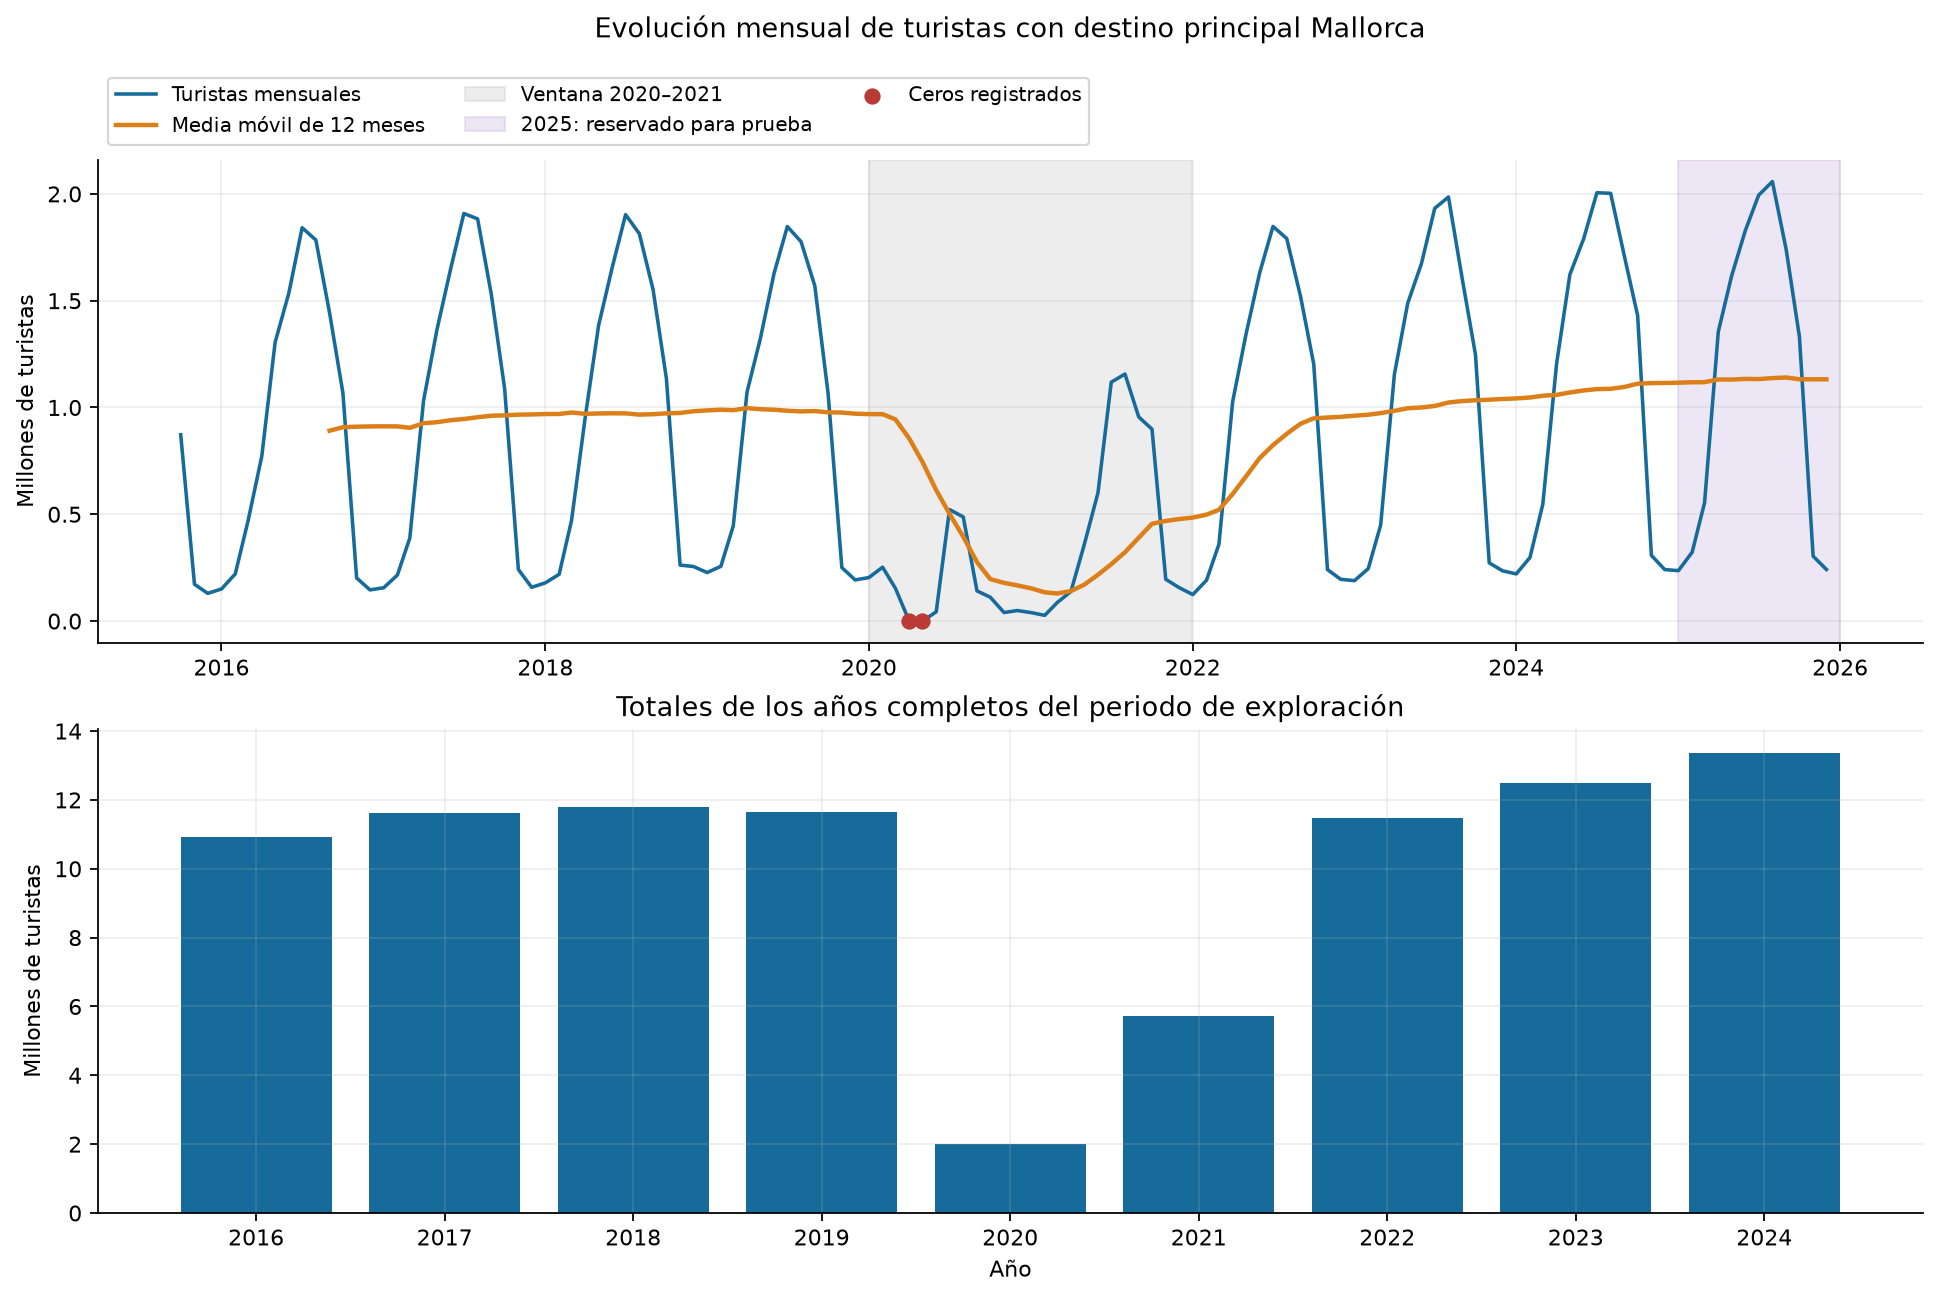

,meses_observados,turistas,variacion_anual_pct
año,,,
2016,12,10937186.0,NaN
2017,12,11609381.0,6.15
2018,12,11788998.0,1.55
2019,12,11651957.0,-1.16
2020,12,2004355.0,-82.80
2021,12,5730732.0,185.91
2022,12,11474346.0,100.22
2023,12,12477497.0,8.74
2024,12,13376944.0,7.21


**Lectura.** La serie combina oscilaciones dentro del año con una ruptura en 2020. En 2024 se registran **13,376,944 turistas**, un **14,8 % más** que en 2019. Los meses de 2015 no permiten calcular un total anual comparable. La media móvil se retrasa ante los cambios bruscos y no debe confundirse con una predicción.

In [12]:
annual = eda_train["turistas"].groupby(eda_train.index.year).agg(["count", "sum"])
annual = annual.loc[annual["count"].eq(12)].copy()
annual["variacion_anual_pct"] = annual["sum"].pct_change(fill_method=None) * 100
annual.index.name = "año"
annual = annual.rename(columns={"count": "meses_observados", "sum": "turistas"})
annual.to_csv(EDA_DIR / "turistas_anuales_hasta_2024.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
axes[0].plot(eda.index, eda["turistas"] / 1e6, color="#176b9b", lw=1.6, label="Turistas mensuales")
axes[0].plot(eda.index, eda["turistas"].rolling(12, min_periods=12).mean() / 1e6,
             color="#dd7f19", lw=2, label="Media móvil de 12 meses")
axes[0].axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color="#c5c5c5", alpha=.3, label="Ventana 2020–2021")
axes[0].axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-12-31"), color="#af91d5", alpha=.22, label="2025: reservado para prueba")
zero_dates = eda.index[eda["turistas"].eq(0)]
axes[0].scatter(zero_dates, eda.loc[zero_dates, "turistas"], color="#ba3b36", s=40, zorder=5, label="Ceros registrados")
axes[0].set_ylabel("Millones de turistas")
axes[0].set_title("Evolución mensual de turistas con destino principal Mallorca", pad=55)
axes[0].legend(fontsize=9, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.01))
axes[1].bar(annual.index, annual["turistas"] / 1e6, color="#176b9b")
axes[1].set(title="Totales de los años completos del periodo de exploración", ylabel="Millones de turistas", xlabel="Año")
axes[1].set_xticks(annual.index)
save_show(fig, "01_evolucion_turistas.png")
display(annual.round(2))
display(Markdown(f"**Lectura.** La serie combina oscilaciones dentro del año con una ruptura en 2020. En 2024 se registran **{annual.loc[2024, 'turistas']:,.0f} turistas**, un **{pct_es((annual.loc[2024, 'turistas'] / annual.loc[2019, 'turistas'] - 1) * 100)} más** que en 2019. Los meses de 2015 no permiten calcular un total anual comparable. La media móvil se retrasa ante los cambios bruscos y no debe confundirse con una predicción."))

## 14. Estacionalidad mensual

Los diagramas de caja usan todos los meses del periodo de exploración, incluidos los de 2020–2021. El segundo panel compara medias de años completos anteriores a la pandemia (2016–2019) y posteriores a la ventana de interrupción (2022–2024). Cada mes dispone de cuatro y tres observaciones, respectivamente; estas muestras pequeñas permiten una lectura descriptiva, sin inferir diferencias estadísticamente significativas.

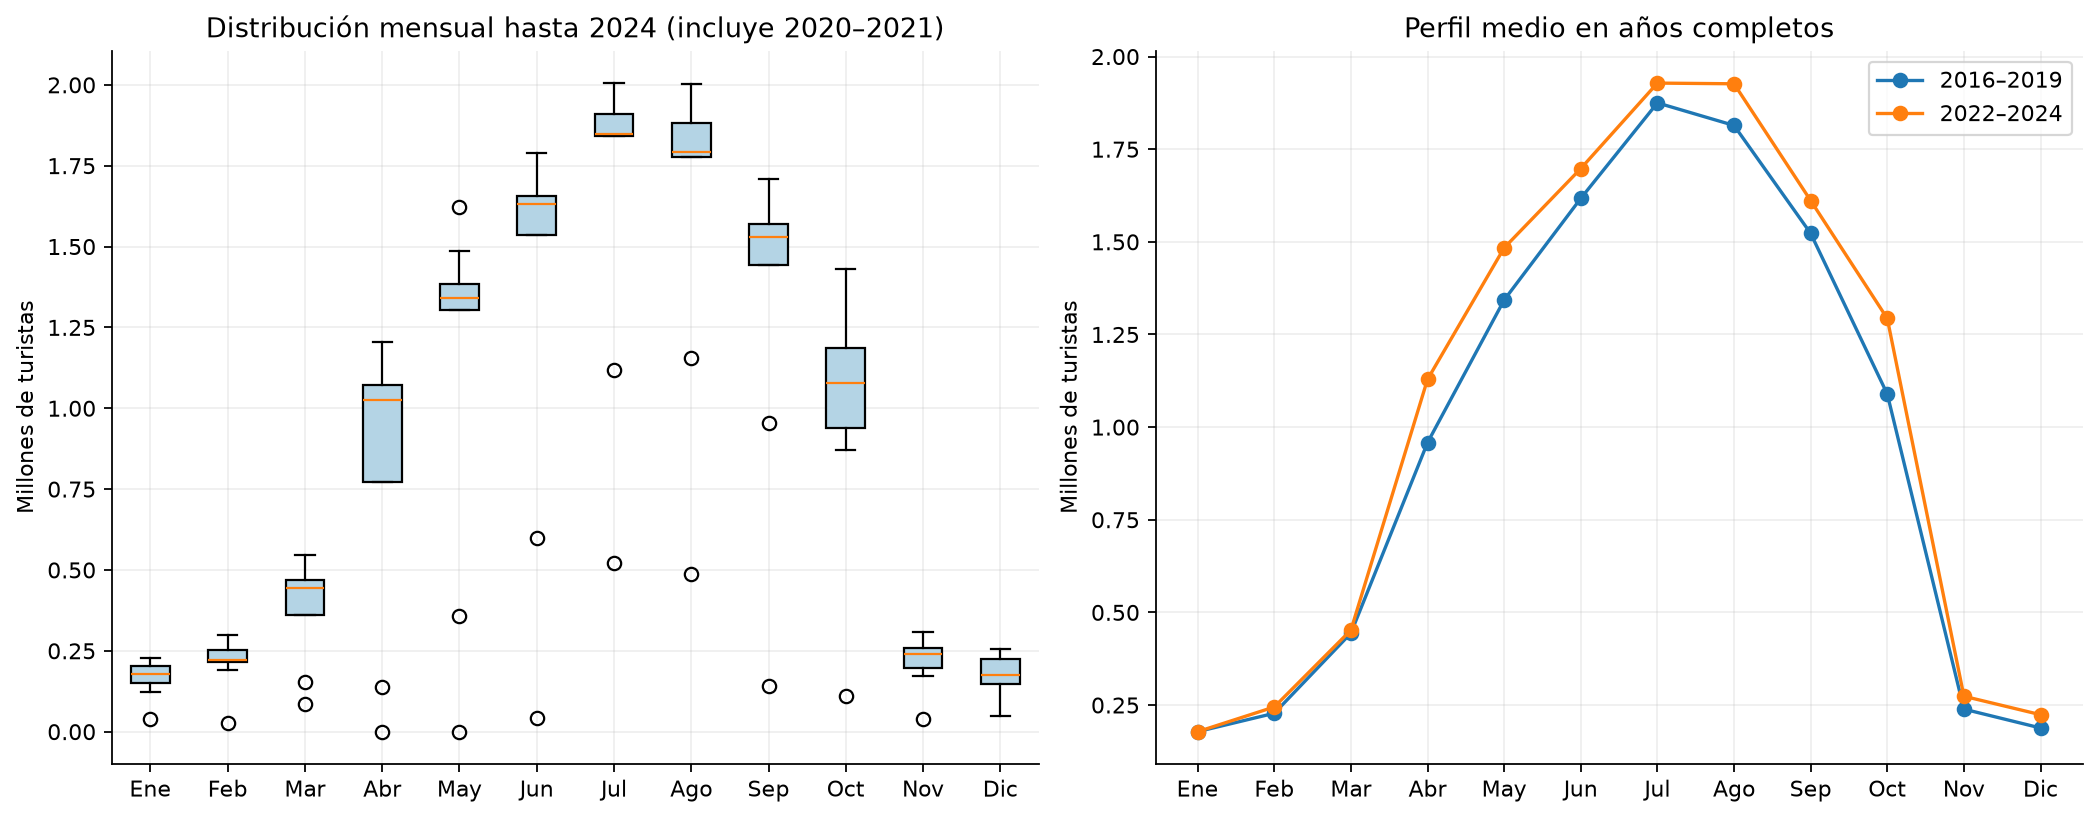

**Lectura.** En 2022–2024 el máximo medio se sitúa en **Jul** y los meses de junio a septiembre reúnen el **57,6 %** del total anual medio. Conviene representar el mes del año y contrastar un baseline estacional con retardo 12. Los valores bajos de 2020 tienen una explicación temporal: que aparezcan como atípicos en una caja no justifica eliminarlos.

In [13]:
profiles = pd.DataFrame({
    "media_2016_2019": eda_train.loc["2016":"2019", "turistas"].groupby(lambda d: d.month).mean(),
    "media_2022_2024": eda_train.loc["2022":"2024", "turistas"].groupby(lambda d: d.month).mean(),
})
profiles.index.name = "mes"
profiles["n_2016_2019"] = eda_train.loc["2016":"2019", "turistas"].groupby(lambda d: d.month).count()
profiles["n_2022_2024"] = eda_train.loc["2022":"2024", "turistas"].groupby(lambda d: d.month).count()
assert profiles["n_2016_2019"].eq(4).all() and profiles["n_2022_2024"].eq(3).all()
profiles.to_csv(EDA_DIR / "perfiles_mensuales.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
boxes = [eda_train.loc[eda_train.index.month == m, "turistas"].dropna().to_numpy() / 1e6 for m in range(1, 13)]
axes[0].boxplot(boxes, patch_artist=True, boxprops={"facecolor": "#b4d4e5"})
axes[0].set_xticks(range(1, 13), MONTHS)
axes[0].set(title="Distribución mensual hasta 2024 (incluye 2020–2021)", ylabel="Millones de turistas")
for col, label in [("media_2016_2019", "2016–2019"), ("media_2022_2024", "2022–2024")]:
    axes[1].plot(profiles.index, profiles[col] / 1e6, marker="o", label=label)
axes[1].set_xticks(range(1, 13), MONTHS)
axes[1].set(title="Perfil medio en años completos", ylabel="Millones de turistas")
axes[1].legend()
save_show(fig, "02_estacionalidad_mensual.png")
summer_share = profiles.loc[6:9, "media_2022_2024"].sum() / profiles["media_2022_2024"].sum() * 100
peak_month = int(profiles["media_2022_2024"].idxmax())
display(Markdown(f"**Lectura.** En 2022–2024 el máximo medio se sitúa en **{MONTHS[peak_month - 1]}** y los meses de junio a septiembre reúnen el **{pct_es(summer_share)}** del total anual medio. Conviene representar el mes del año y contrastar un baseline estacional con retardo 12. Los valores bajos de 2020 tienen una explicación temporal: que aparezcan como atípicos en una caja no justifica eliminarlos."))

## 15. Caída y recuperación tras la pandemia

El índice mensual divide los turistas de cada mes entre los del mismo mes de 2019 (2019 = 100). Se presenta hasta 2024. Un índice mayor que 100 indica que se supera ese mes de referencia; no implica que todos los meses o todos los indicadores se hayan recuperado. Los ceros de abril y mayo de 2020 se mantienen con su estado de fuente `U`.

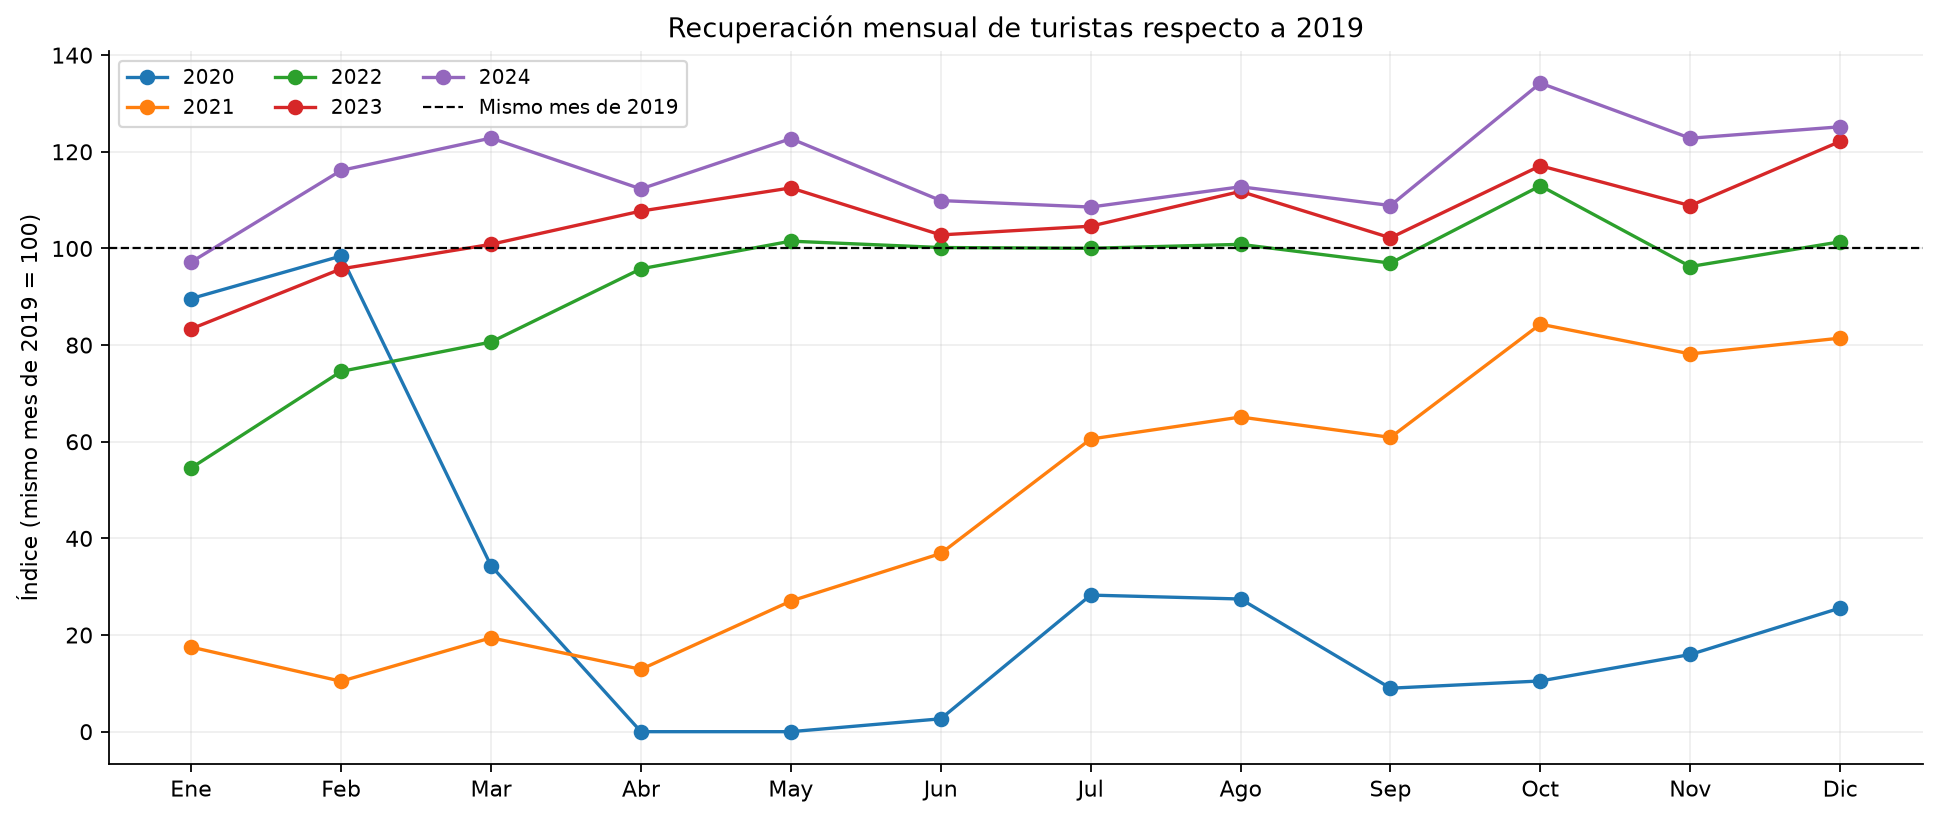

**Lectura.** El total de turistas de 2020 cae un **82,8 %** respecto a 2019. El primer año posterior a 2020 que iguala o supera el total de 2019 es **2023**. El gráfico permite comprobar qué meses explican la recuperación. Para preparar los datos interesa conservar la ruptura y evaluar después la sensibilidad a incluir 2020–2021, sin decidir a partir del rendimiento de 2025. Las métricas basadas en dividir por el valor real, como MAPE, requieren especial cuidado ante los meses con cero turistas.

In [14]:
reference_2019 = eda_train.loc["2019", "turistas"]
assert len(reference_2019) == 12 and reference_2019.gt(0).all()
reference_by_month = reference_2019.groupby(lambda d: d.month).first()
pandemic = eda_train.loc["2020":"2024", ["turistas"]].copy()
pandemic["turistas_2019_mismo_mes"] = pandemic.index.month.map(reference_by_month)
pandemic["indice_2019_100"] = pandemic["turistas"] / pandemic["turistas_2019_mismo_mes"] * 100
pandemic.to_csv(EDA_DIR / "recuperacion_mensual.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
for year in range(2020, 2025):
    part = pandemic.loc[str(year)]
    ax.plot(part.index.month, part["indice_2019_100"], marker="o", label=str(year))
ax.axhline(100, color="black", ls="--", lw=1, label="Mismo mes de 2019")
ax.set_xticks(range(1, 13), MONTHS)
ax.set(title="Recuperación mensual de turistas respecto a 2019", ylabel="Índice (mismo mes de 2019 = 100)")
ax.legend(ncol=3, fontsize=9)
save_show(fig, "03_pandemia_recuperacion.png")
drop_2020 = (annual.loc[2020, "turistas"] / annual.loc[2019, "turistas"] - 1) * 100
recovered_years = annual.loc[2021:].index[annual.loc[2021:, "turistas"].ge(annual.loc[2019, "turistas"])]
first_recovery = int(recovered_years[0]) if len(recovered_years) else None
display(Markdown(f"**Lectura.** El total de turistas de 2020 cae un **{pct_es(abs(drop_2020))}** respecto a 2019. El primer año posterior a 2020 que iguala o supera el total de 2019 es **{first_recovery}**. El gráfico permite comprobar qué meses explican la recuperación. Para preparar los datos interesa conservar la ruptura y evaluar después la sensibilidad a incluir 2020–2021, sin decidir a partir del rendimiento de 2025. Las métricas basadas en dividir por el valor real, como MAPE, requieren especial cuidado ante los meses con cero turistas."))

## 16. Relación con el aeropuerto y la actividad hotelera

Se estudian relaciones contemporáneas hasta 2024. Los pasajeros de Palma incluyen movimientos de residentes y otras tipologías y no equivalen al número de turistas. Los viajeros hoteleros excluyen otras formas de alojamiento; las pernoctaciones cuentan noches, no personas. Por tanto, los indicadores se relacionan, pero no son intercambiables.

Se comparan las correlaciones de Pearson en niveles con las de las **diferencias interanuales** (`x_t − x_{t−12}`), calculadas sobre el calendario completo sin rellenar huecos. Esta segunda lectura reduce el patrón estacional compartido, aunque conserva efectos comunes como la pandemia. Se informa de los pares observados para cada coeficiente. No se seleccionan retardos ni variables mediante estas correlaciones.

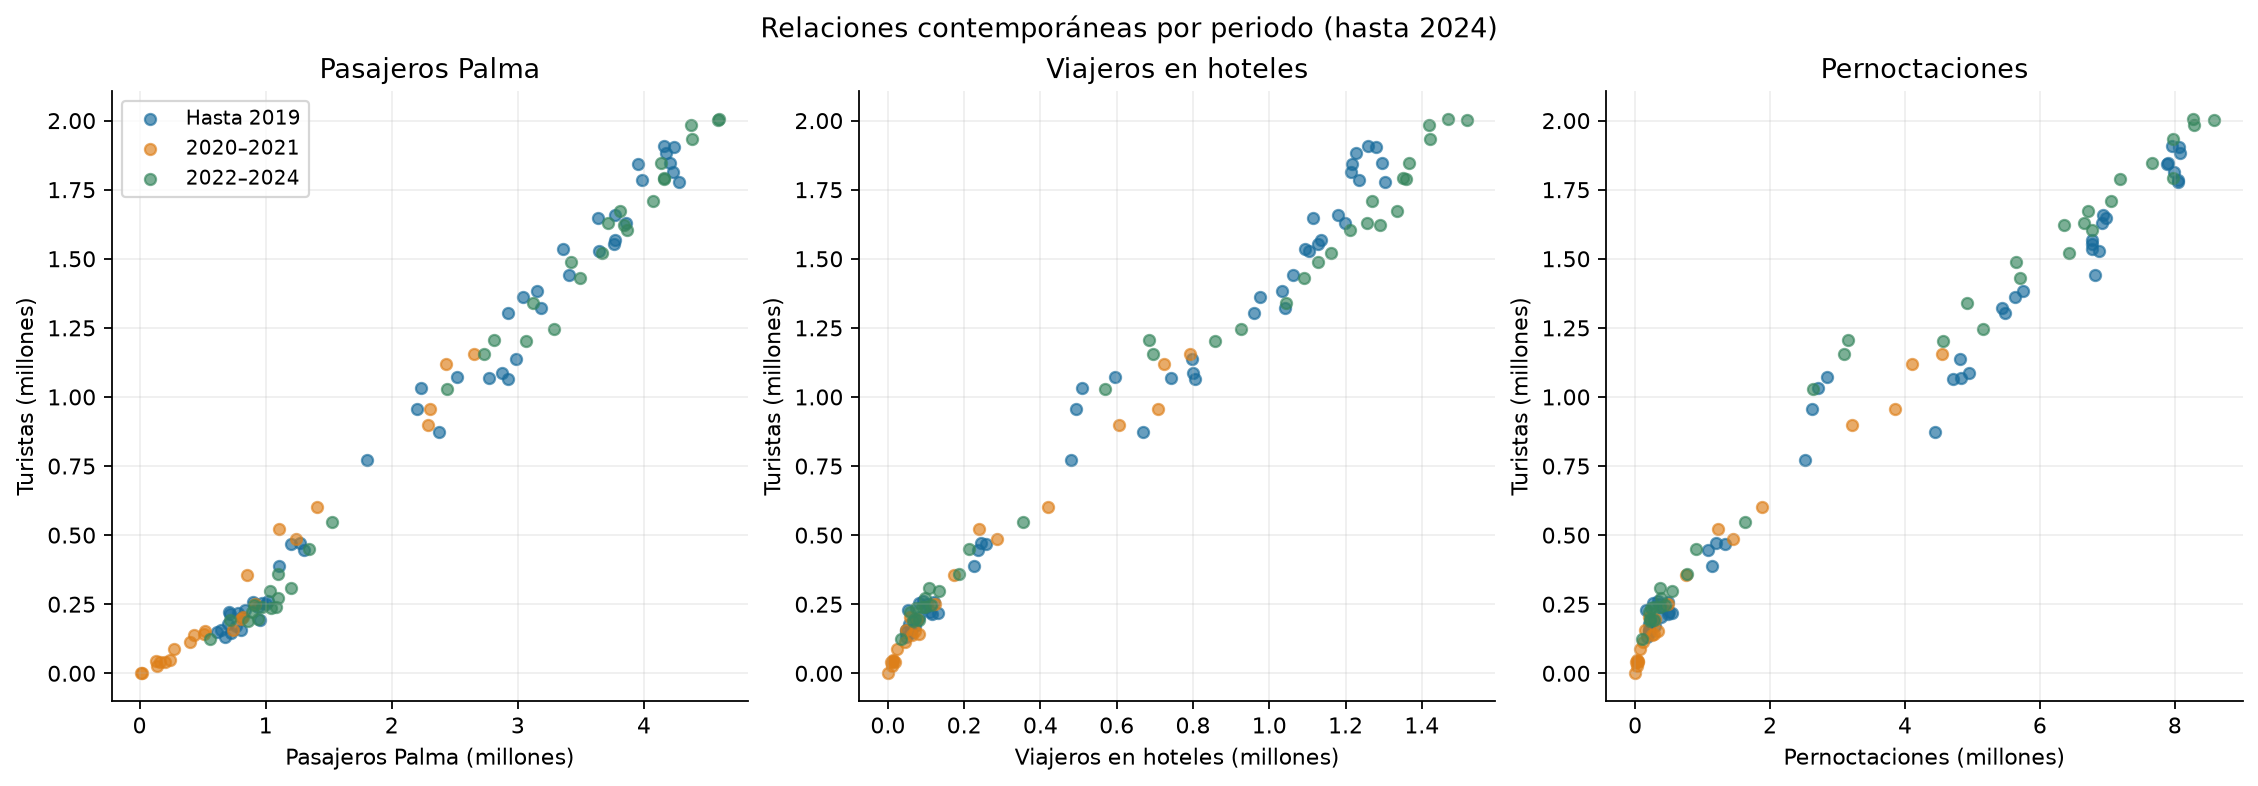

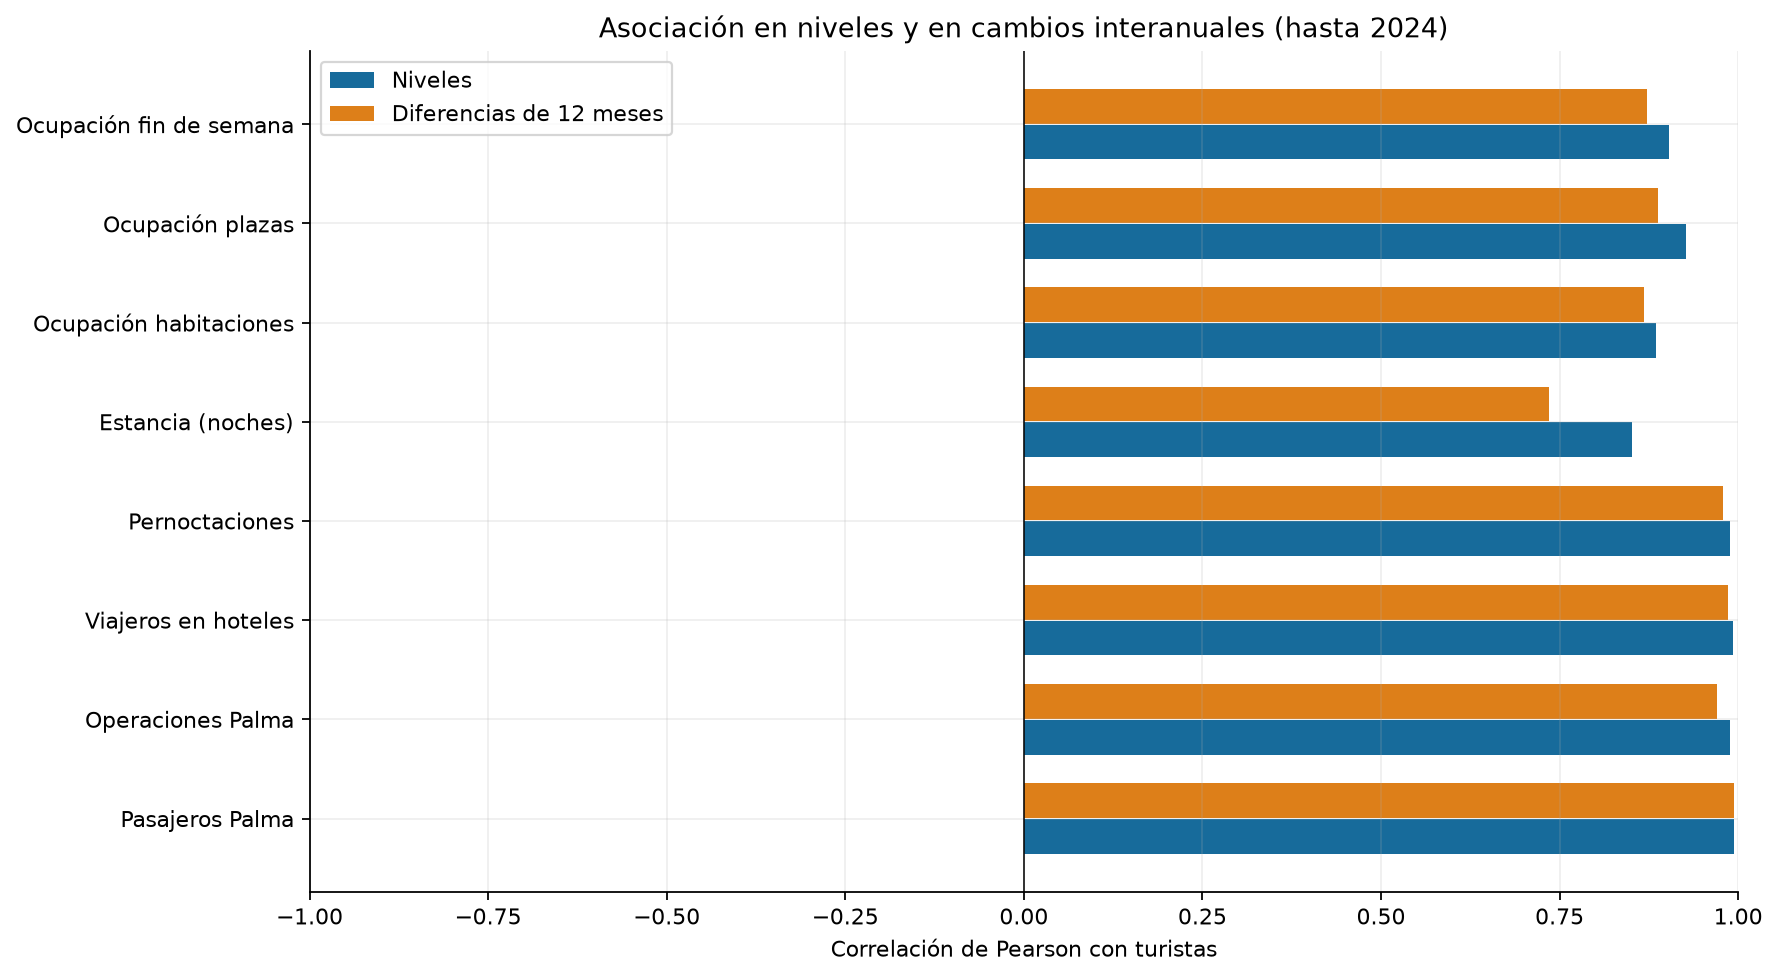

,pearson_niveles,pares_niveles,pearson_diferencia_12,pares_diferencia_12
variable,,,,
Pasajeros Palma,0.994,111,0.994,99
Operaciones Palma,0.988,111,0.970,99
Viajeros en hoteles,0.993,110,0.985,97
Pernoctaciones,0.989,110,0.978,97
Estancia (noches),0.851,109,0.735,95
Ocupación habitaciones,0.885,109,0.867,95
Ocupación plazas,0.926,109,0.888,95
Ocupación fin de semana,0.903,109,0.872,95


**Lectura.** La correlación de turistas con pasajeros de Palma es **0.994** en niveles y **0.994** en diferencias interanuales; con las pernoctaciones es **0.989** en niveles. La asociación describe movimientos compartidos, no el beneficio predictivo de añadir estas variables. Ese beneficio deberá medirse fuera de muestra con valores disponibles en cada fecha de predicción. La estancia media se deriva de pernoctaciones y viajeros, por lo que estas medidas tampoco aportan información completamente independiente.

In [15]:
external = [c for c in VALUE_COLUMNS if c != "turistas" and c not in GT_COLUMNS]
seasonal_diff = eda_train.diff(12)
correlations = pd.DataFrame(index=external)
for frame, suffix in [(eda_train, "niveles"), (seasonal_diff, "diferencia_12")]:
    correlations[f"pearson_{suffix}"] = [frame[["turistas", c]].corr().loc["turistas", c] for c in external]
    correlations[f"pares_{suffix}"] = [len(frame[["turistas", c]].dropna()) for c in external]
correlations.index.name = "variable"
correlations.to_csv(EDA_DIR / "correlaciones_turistas.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)
periods = [("2015-10", "2019-12", "Hasta 2019", "#176b9b"),
           ("2020-01", "2021-12", "2020–2021", "#dd7f19"),
           ("2022-01", "2024-12", "2022–2024", "#35855c")]
for ax, col in zip(axes, ["pasajeros_aena", "viajeros_hoteles", "pernoctaciones_hoteles"]):
    for start, end, label, color in periods:
        pair = eda_train.loc[start:end, ["turistas", col]].dropna()
        ax.scatter(pair[col] / 1e6, pair["turistas"] / 1e6, s=25, alpha=.65, color=color, label=label)
    ax.set(xlabel=LABELS[col] + " (millones)", ylabel="Turistas (millones)", title=LABELS[col])
axes[0].legend(fontsize=9)
fig.suptitle("Relaciones contemporáneas por periodo (hasta 2024)")
save_show(fig, "04_relaciones_aeropuerto_hoteles.png")

fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
positions = np.arange(len(external))
ax.barh(positions - .18, correlations["pearson_niveles"], height=.35, label="Niveles", color="#176b9b")
ax.barh(positions + .18, correlations["pearson_diferencia_12"], height=.35, label="Diferencias de 12 meses", color="#dd7f19")
ax.set_yticks(positions, [LABELS[c] for c in external])
ax.set(xlim=(-1, 1), xlabel="Correlación de Pearson con turistas", title="Asociación en niveles y en cambios interanuales (hasta 2024)")
ax.axvline(0, color="black", lw=.7)
ax.legend(loc="upper left")
save_show(fig, "05_correlaciones.png")
display(correlations.rename(index=LABELS).round(3))
air_r = correlations.loc["pasajeros_aena", "pearson_niveles"]
air_diff_r = correlations.loc["pasajeros_aena", "pearson_diferencia_12"]
hotel_r = correlations.loc["pernoctaciones_hoteles", "pearson_niveles"]
display(Markdown(f"**Lectura.** La correlación de turistas con pasajeros de Palma es **{air_r:.3f}** en niveles y **{air_diff_r:.3f}** en diferencias interanuales; con las pernoctaciones es **{hotel_r:.3f}** en niveles. La asociación describe movimientos compartidos, no el beneficio predictivo de añadir estas variables. Ese beneficio deberá medirse fuera de muestra con valores disponibles en cada fecha de predicción. La estancia media se deriva de pernoctaciones y viajeros, por lo que estas medidas tampoco aportan información completamente independiente."))

## 17. Ausentes, ceros y estados de calidad

El mapa distingue un dato numérico observado de un ausente (`NaN`): el cero es un valor observado. Los estados `U` y `P` se revisan aparte, ya que no convierten automáticamente un número en un ausente. En AENA el estado es común al informe mensual. Las tablas cubren todo el periodo para comprobar la calidad y muestran también los ausentes del conjunto de exploración.

### Decisión sobre los ceros y la ruptura de 2020

La revisión del 9 de octubre de 2026 identifica dos ceros en la variable objetivo: abril y mayo de 2020, el 1,6 % de los 123 meses. Ambos llevan estado `U` (baja fiabilidad según la documentación de origen). Coinciden con el episodio de restricciones pandémicas, pero su conservación no implica considerarlos recuentos exactos plenamente fiables. La serie de turistas no tiene valores ausentes.

| Variable | Meses con cero | Meses ausentes (`NaN`) |
|---|---|---|
| Turistas | Abril y mayo de 2020, ambos con `U` | Ninguno |
| Viajeros y pernoctaciones hoteleras | Abril de 2020 | Mayo de 2020 |
| Cada uno de los tres indicadores de ocupación | Abril de 2020 | Mayo y diciembre de 2020 |
| Estancia media en noches | Ninguno | Abril y mayo de 2020 |

Pasajeros, operaciones aeroportuarias y los cuatro índices de Google Trends no presentan ceros ni ausentes en este maestro. Estos recuentos corresponden a las descargas actuales y deberán comprobarse si se actualizan las fuentes.

**Tratamiento acordado.** El dataset maestro conserva los valores publicados, sus estados y el calendario mensual completo. No se eliminan abril y mayo ni se sustituyen sus ceros por promedios o interpolaciones. Suprimir filas y concatenar los meses restantes alteraría las distancias temporales y la interpretación de los retardos. Los ausentes hoteleros permanecen como `NaN`: no se convierten automáticamente en cero. La estancia media, en particular, puede no estar definida cuando no hay viajeros; debe comprobarse el motivo en la fuente antes de asignar un valor.

**Experimento principal y sensibilidad.** La configuración base conservará el episodio pandémico y las marcas de calidad para su auditoría. En validación anterior a 2025 se comparará con una alternativa de entrenamiento posterior a la pandemia. La fecha de inicio y la historia mínima se concretarán antes de la prueba final, atendiendo a la estacionalidad anual y al menor tamaño de la muestra. Ambas configuraciones se evaluarán en los mismos meses objetivo, por separado para h=1 y h=3, respetando la disponibilidad de cada predictor. No se elegirá el tratamiento a partir de los resultados de 2025. Esta comparación evalúa el efecto de cambiar el periodo de entrenamiento; no permite atribuir cualquier diferencia únicamente a los dos ceros.

**Ausentes hoteleros.** Antes del modelado se comprobará si cada hueco expresa falta de información, baja fiabilidad o imposibilidad de calcular el indicador. Si persiste, se documentará un tratamiento por variable dentro de cada partición de entrenamiento, sin utilizar datos posteriores al origen. La comparación con modelos basados solo en histórico y calendario permitirá comprobar si incorporar estas fuentes aporta una mejora. La técnica concreta de imputación todavía no está elegida.

**Métricas.** MAE y RMSE serán las medidas principales en la escala original de turistas. MAPE no se utilizará como criterio principal porque divide por el valor observado y es indefinido cuando este es cero; tampoco se reemplazarán ceros por cantidades arbitrarias para poder calcularlo. Si se incorpora MASE, su denominador estacional se calculará únicamente con el entrenamiento de cada partición y se comprobará que sea distinto de cero.

**Relación con los antecedentes.** Perú (Pinedo et al., 2026) empieza en 2022 y excluye 2020–2021 mediante el periodo elegido. Austria (Reichold, 2026) incluye la pandemia en la comparación principal y ensaya ajustes retrospectivos en robustez. Reino Unido (Dimitriadou et al., 2026) declara una muestra hasta febrero de 2020, y el TFG de Mallorca (Ramos Hoogwout, 2020) estima con datos hasta diciembre de 2019. Ninguno justifica eliminar nuestros dos ceros simplemente por su escasa frecuencia. El detalle y las reservas de estos estudios están recogidos en `docs/revision_bibliografica/estudios.md` y en las fichas de apoyo.

Como fundamento metodológico, Hyndman y Athanasopoulos explican que las observaciones excepcionales deben interpretarse antes de sustituirlas y que los errores porcentuales no están definidos con objetivos iguales a cero: [tratamiento de observaciones excepcionales y ausentes](https://otexts.com/fpp3/missing-outliers.html) y [evaluación de pronósticos](https://otexts.com/fpp3/accuracy.html).

La decisión queda documentada; la comparación de sensibilidad y el tratamiento de los ausentes están pendientes de implementación. El maestro conserva sus valores originales.


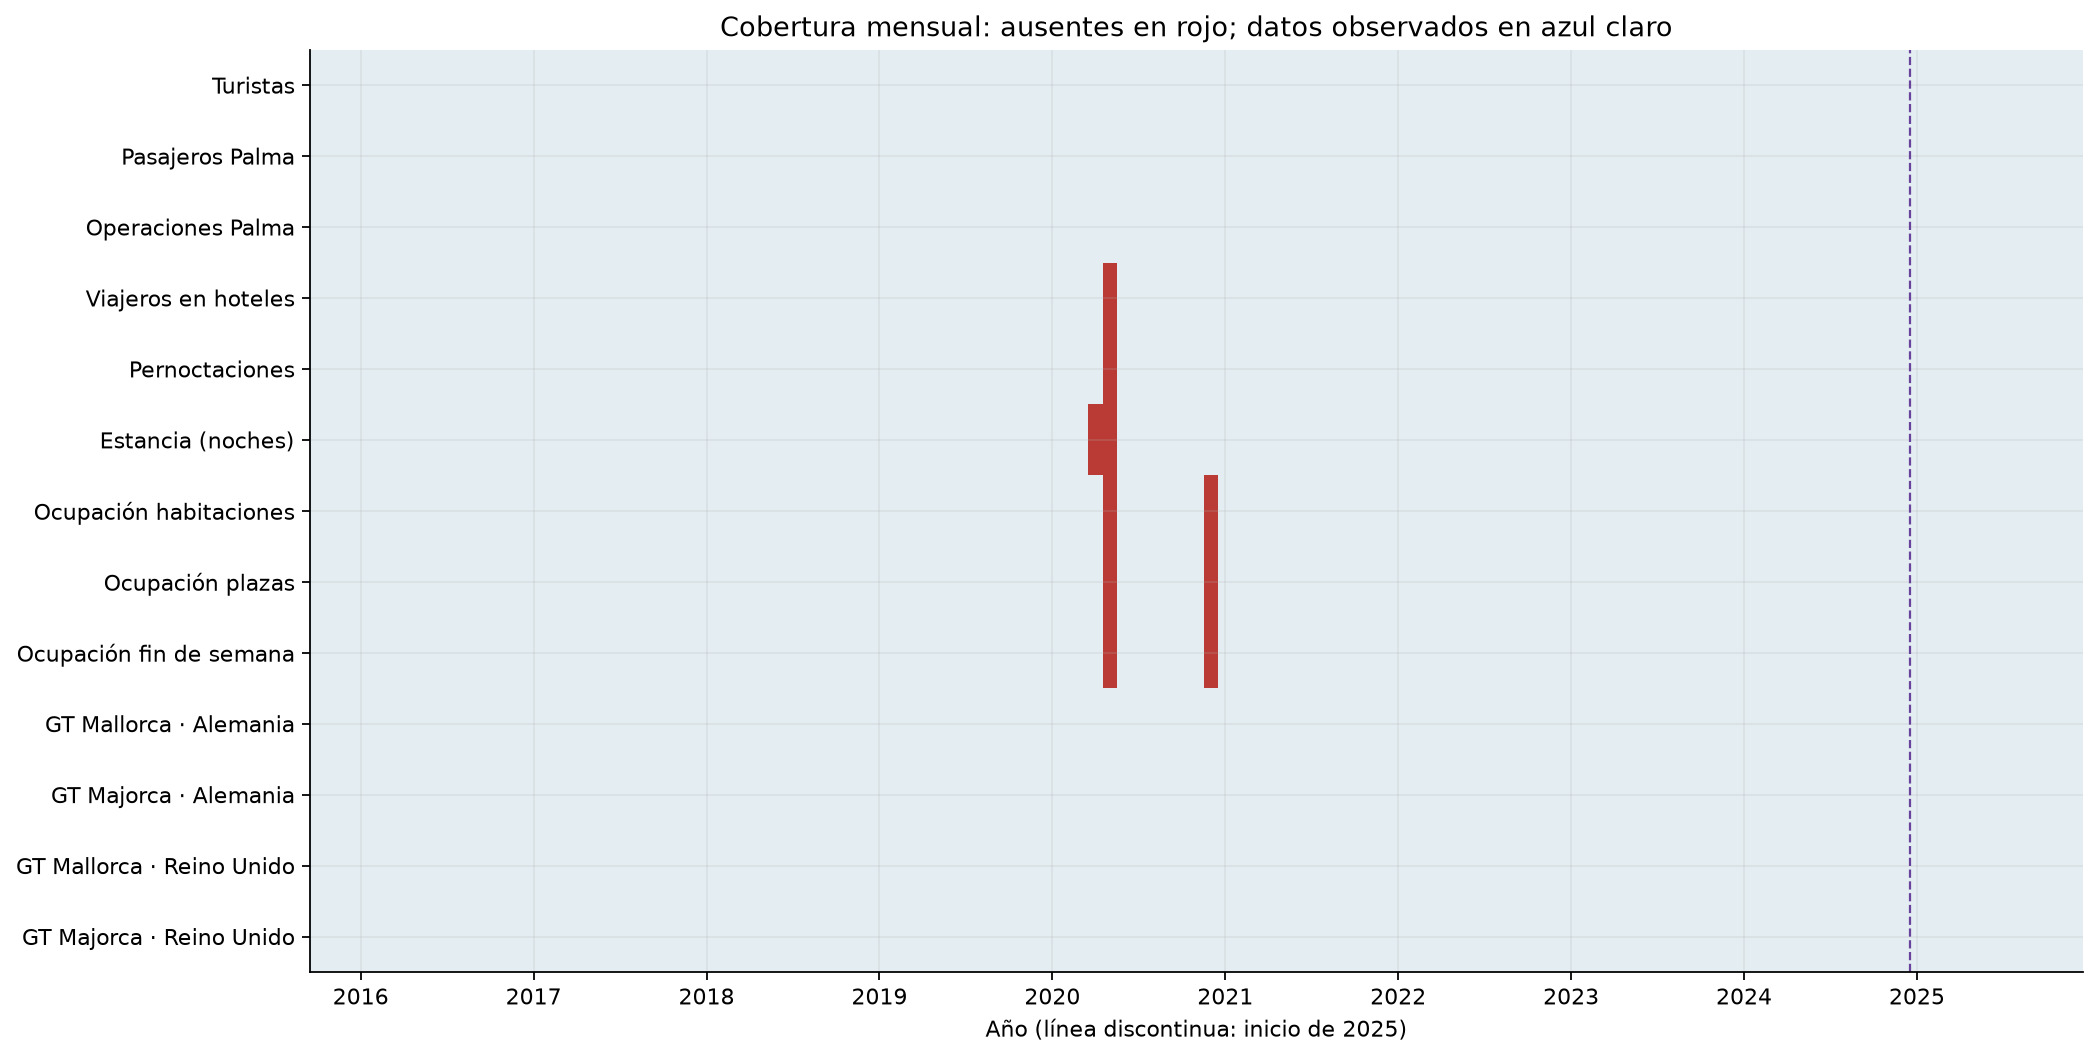

,observados,ausentes_total,ausentes_hasta_2024,ceros,estado_U,estado_P_o_provisional
variable,,,,,,
Turistas,123,0,0,2,2,0
Pasajeros Palma,123,0,0,0,0,12
Operaciones Palma,123,0,0,0,0,12
Viajeros en hoteles,122,1,1,1,1,12
Pernoctaciones,122,1,1,1,1,12
Estancia (noches),121,2,2,0,2,12
Ocupación habitaciones,121,2,2,1,2,7
Ocupación plazas,121,2,2,1,2,7
Ocupación fin de semana,121,2,2,1,2,7


,fecha,variable,estado
0,2020-05-01,viajeros_hoteles,U
1,2020-05-01,pernoctaciones_hoteles,U
2,2020-04-01,estancia_media_noches,U
3,2020-05-01,estancia_media_noches,U
4,2020-05-01,ocupacion_habitaciones_pct,U
5,2020-12-01,ocupacion_habitaciones_pct,U
6,2020-05-01,ocupacion_plazas_pct,U
7,2020-12-01,ocupacion_plazas_pct,U
8,2020-05-01,ocupacion_fin_semana_pct,U
9,2020-12-01,ocupacion_fin_semana_pct,U


,turistas,turistas_estado,viajeros_hoteles,pernoctaciones_hoteles
fecha,,,,
2020-04-01,0.0,U,0.0,0.0
2020-05-01,0.0,U,NaN,NaN


**Lectura.** No hay ausentes en turistas ni en los indicadores de AENA. En mayo de 2020 faltan viajeros y pernoctaciones; la estancia media falta en abril y mayo de 2020, y los tres indicadores de ocupación, en mayo y diciembre de 2020. No se deben convertir esos huecos en ceros ni interpolarlos sin estudiar su contexto. Los ceros de turistas de abril y mayo de 2020 se conservan y quedan identificados con estado `U`. Los informes de AENA de 2025 figuran como provisionales: debe registrarse la versión utilizada en la evaluación final.

In [16]:
missing_review = []
for col in VALUE_COLUMNS:
    state_col = "aena_estado" if col in ["pasajeros_aena", "operaciones_aena"] else col + "_estado"
    counts = eda[state_col].value_counts() if state_col in eda else pd.Series(dtype=int)
    missing_review.append({"variable": col, "observados": int(eda[col].count()),
        "ausentes_total": int(eda[col].isna().sum()), "ausentes_hasta_2024": int(eda_train[col].isna().sum()),
        "ceros": int(eda[col].eq(0).sum()), "estado_U": int(counts.get("U", 0)),
        "estado_P_o_provisional": int(counts.get("P", 0) + counts.get("provisional", 0))})
missing_review = pd.DataFrame(missing_review).set_index("variable")
missing_review.to_csv(EDA_DIR / "revision_ausentes_ceros_estados.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(13, 6.5), constrained_layout=True)
im = ax.imshow(eda[VALUE_COLUMNS].isna().T.to_numpy().astype(int),
               aspect="auto", interpolation="nearest", cmap=ListedColormap(["#e4edf2", "#ba3b36"]), vmin=0, vmax=1)
ticks = [i for i, d in enumerate(eda.index) if d.month == 1]
ax.set_xticks(ticks, [str(eda.index[i].year) for i in ticks])
ax.set_yticks(range(len(VALUE_COLUMNS)), [LABELS[c] for c in VALUE_COLUMNS])
ax.axvline(eda.index.get_loc(pd.Timestamp("2025-01-01")) - .5, color="#68439b", ls="--", lw=1)
ax.set(title="Cobertura mensual: ausentes en rojo; datos observados en azul claro", xlabel="Año (línea discontinua: inicio de 2025)")
save_show(fig, "06_mapa_ausentes.png")
display(missing_review.rename(index=LABELS))
display(missing_details)
zero_review = eda.loc[eda["turistas"].eq(0), ["turistas", "turistas_estado", "viajeros_hoteles", "pernoctaciones_hoteles"]]
display(zero_review)
assert eda["turistas"].notna().all() and eda["pasajeros_aena"].notna().all()
display(Markdown("**Lectura.** No hay ausentes en turistas ni en los indicadores de AENA. En mayo de 2020 faltan viajeros y pernoctaciones; la estancia media falta en abril y mayo de 2020, y los tres indicadores de ocupación, en mayo y diciembre de 2020. No se deben convertir esos huecos en ceros ni interpolarlos sin estudiar su contexto. Los ceros de turistas de abril y mayo de 2020 se conservan y quedan identificados con estado `U`. Los informes de AENA de 2025 figuran como provisionales: debe registrarse la versión utilizada en la evaluación final."))

## 18. Conclusiones para la preparación de datos

1. **Mantener el calendario mensual completo.** La variable objetivo y el aeropuerto cubren los 123 meses. Eliminar filas por los ausentes hoteleros rompería la regularidad de la serie y los retardos de doce meses. Los meses iniciales sin historia suficiente para construir retardos se tratarán después como pérdida de contexto, no como errores del ETL.
2. **Representar la estacionalidad y comprobarla fuera de muestra.** El perfil mensual justifica contrastar Seasonal Naive y modelos con componente estacional. Para aprendizaje automático se pueden preparar mes del año, retardos del objetivo y resúmenes móviles calculados con `shift(1)`. Sus ventanas y parámetros se elegirán en validación temporal anterior a 2025.
3. **Conservar y documentar la ruptura de 2020.** Los ceros de abril y mayo de 2020 no son huecos y llevan estado `U`, por lo que su precisión es limitada. Se conservarán en el maestro y en la configuración base. En validación anterior a 2025 se comparará con un entrenamiento posterior a la pandemia sobre los mismos meses objetivo, según la decisión documentada en el apartado 17. Cualquier indicador de restricciones requiere fechas verificables y una regla de disponibilidad; no debe inventarse a partir del descenso observado ni prolongarse al futuro sin justificación.
4. **Tratar los ausentes por variable y dentro de cada partición.** Los pocos huecos se concentran en meses de pandemia y afectan a indicadores distintos. Primero se debe consultar la fuente y documentar si representan falta de información o imposibilidad de estimar la medida. Si persisten, comparar un modelo solo con objetivo y calendario con modelos que incorporen variables externas y un tratamiento aprendido únicamente con entrenamiento. Evitar interpolaciones que utilicen meses posteriores a la fecha pronosticada.
5. **Alinear las variables externas con su disponibilidad real.** La correlación contemporánea no permite utilizar pasajeros, ocupación o pernoctaciones del mes que se intenta predecir. Antes del modelado se deben fijar horizontes y retardos de publicación, y construir una tabla de información disponible en cada origen de predicción. Las series descargadas no reconstruyen las versiones históricas: la evaluación será retrospectiva y esta limitación debe explicarse.
6. **No confundir medidas ni duplicar información sin evaluarla.** Pasajeros, viajeros hoteleros y turistas representan poblaciones diferentes. Pernoctaciones y estancia media están relacionadas con viajeros; se contrastará su aportación mediante validación temporal, no solo por correlaciones altas. Escalado, imputación y selección de variables se ajustarán en cada partición de entrenamiento.
7. **Cerrar pendientes antes de consolidar el dataset de modelos.** Falta integrar y revisar la meteorología cuando esté disponible. Mantener los estados de calidad y la versión de los archivos; justificar las métricas ante los ceros del objetivo y reservar 2025 para la comparación final. El EDA termina aquí: no se han imputado valores, ajustado modelos ni elegido hiperparámetros.

Las figuras y tablas de este bloque se regeneran en `outputs/eda/`. Los resultados numéricos comentados se calculan al ejecutar el notebook, para que no queden desvinculados de las fuentes.

In [17]:
eda_metadata = {
    "periodo_descriptivo": [str(eda.index.min().date()), str(eda.index.max().date())],
    "periodo_relaciones": [str(eda_train.index.min().date()), str(eda_train.index.max().date())],
    "meses_exploracion": len(eda_train), "meses_prueba_reservados": 12,
    "referencia_recuperacion": 2019, "ventana_interrupcion_descriptiva": [2020, 2021],
    "imputacion": "no realizada", "modelos": "no ajustados", "aemet": "pendiente",
    "correlaciones": "Pearson por pares completos, niveles y diferencias de 12 meses",
    "python": platform.python_version(),
    "dependencias": {p: importlib.metadata.version(p) for p in ["pandas", "numpy", "matplotlib"]},
    "dataset_sha256": hashlib.sha256((OUTPUT_DIR / "dataset_maestro_mallorca.csv").read_bytes()).hexdigest(),
    "figuras": figures,
}
(EDA_DIR / "ejecucion.json").write_text(json.dumps(eda_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
assert eda[VALUE_COLUMNS].equals(master[VALUE_COLUMNS])
print(f"EDA completado: {len(figures)} figuras y 5 tablas; datos originales del maestro conservados.")
print("Salidas:", EDA_DIR)

EDA completado: 6 figuras y 5 tablas; datos originales del maestro conservados.
Salidas: C:\Users\acort\Documents\Codex\tfm-turismo-mallorca\outputs\eda


## 19. Disponibilidad de los predictores y decisión sobre retardos

**Fecha de comprobación: 8 de octubre de 2026.** Se fija el origen de pronóstico al cierre del último día natural de cada mes `t`, en hora de Mallorca. Se pronostica el total mensual de turistas de `t+1` y `t+3`. El cierre del mes no hace que sus estadísticas ya estén publicadas. Por ejemplo, al cierre de enero no se pueden usar los pasajeros ni los hoteles de enero.

La revisión de fuentes da lugar a una **política mensual de disponibilidad**, distinta de la elección de retardos predictivos. El desfase de publicación es un mínimo obligatorio; los retardos adicionales se seleccionarán en validación anterior a 2025.

| Grupo | Evidencia sobre publicación | Último mes utilizable al cierre de t | Retardo mínimo respecto al mes objetivo: h=1 / h=3 |
|---|---|---|---|
| Pasajeros y operaciones AENA Palma | Enero de 2025 se difundió el 12 de febrero de 2025. Febrero de 2026 se difundió el 12 de marzo. Son ejemplos efectivos, no una garantía de publicación siempre el día 12. | t−1 | 2 / 4 meses |
| Viajeros, pernoctaciones, estancia media y las tres ocupaciones de IBESTAT | El calendario oficial de 2025 programa la EOH en el mes siguiente al de referencia; las fechas previstas van del 21 al 25. El INE describe unos 23 días para las cifras provisionales. | t−1 | 2 / 4 meses |
| Histórico de turistas IBESTAT, utilizado como predictor y para entrenar | El calendario oficial de 2025 programa el flujo turístico con dos meses de desfase. La noticia de IBESTAT del 2 de octubre de 2026 publica agosto de 2026, incluyendo turistas nacionales e internacionales. | t−2 | 3 / 5 meses |
| Mes, año y demás calendario conocido | El calendario del mes objetivo se conoce al emitir el pronóstico. | Mes objetivo | Sin espera de publicación |
| Meteorología | Pendiente de obtener los datos y comprobar su difusión. | Sin definir | No se incorpora todavía |

### Fuentes contrastadas

- [AENA Palma, enero de 2025, publicación del 12 de febrero](https://www.aena.es/es/prensa/el-aeropuerto-de-palma-de-mallorca-registra-durante-el-primer-mes-de-2025---mas-de-900.000-pasajeros.html%26p%3D1575078740846).
- [AENA Palma, febrero de 2026, publicación del 12 de marzo](https://www.aena.es/doc/detalleprensa/260312-pmi-estadisticas-febrero.pdf).
- [Programa anual de estadística de IBESTAT 2025](https://ibestat.es/wp-content/uploads/2025/01/programa_2025_castella.pdf), calendario del IBESTAT, página 158 del PDF (página 2765 del BOIB). La columna indica el mes de difusión; dentro de la celda figuran el día de difusión y el periodo de referencia. Las fechas son previstas y el estado P corresponde a datos provisionales. La celda de noviembre para flujo turístico contiene un día 31, inválido para noviembre: no se utiliza como una fecha válida ni se corrige por suposición.
- [Informe metodológico del INE sobre EOH](https://www.ine.es/dynt3/metadatos/es/RespuestaDatos.htm?oe=30235), apartados 14 y 17: oportunidad y revisiones. [Publicación efectiva de enero de 2025, el 25 de febrero](https://www.ine.es/dyngs/Prensa/CTH0125.htm) y [diciembre de 2025, el 26 de enero de 2026](https://www.ine.es/dyngs/Prensa/CTH1225.htm). Las fechas del INE sirven de contraste, pero no se atribuyen a la publicación de nuestros cubos de IBESTAT.
- [Noticia de IBESTAT para agosto de 2026](https://ibestat.es/turistes-amb-destinacio-principal-a-les-illes-balears-frontur-agost-2026/?lang=ca) y [página de IBESTAT con su fecha 02/10/2026](https://ibestat.es/). [FRONTUR del INE de enero de 2025, difundido el 4 de marzo](https://www.ine.es/dyngs/Prensa/FRONTUR0125.htm) confirma el patrón nacional, pero cubre turistas internacionales y no sustituye a la variable objetivo insular de este trabajo.

### Qué se ha comprobado y qué se está suponiendo

Se han contrastado el calendario autonómico de 2025, la metodología hotelera y ejemplos de difusión efectiva. **No se ha reconstruido la primera publicación de cada observación de 2015–2025**, ni las versiones de los valores disponibles en cada fecha histórica. Aplicar estos desfases a todo el histórico es una simulación retrospectiva bajo una regla explícita, no una reproducción exacta de lo que se sabía entonces.

En ausencia de una fecha efectiva comprobada, la fecha operativa se fija al último día del mes de difusión supuesto: un mes después para AENA y hoteles y dos después para turistas. Es conservadora dentro de ese mes, pero no garantiza que nunca haya existido una publicación excepcionalmente tardía. Una fecha comprobada posterior prevalecerá y bloqueará el dato hasta entonces. Como sensibilidad se retrasarán todos los grupos un mes adicional, sin decidir esa comprobación mediante los resultados de 2025. La tabla de evidencia separa fechas efectivas de fechas previstas.

Los Excel descargados contienen revisiones y algunos informes AENA son definitivos. Con retrasar su periodo de referencia no se reconstruye el valor provisional original: seguirá existiendo una limitación por revisiones. Las fechas de modificación de los archivos y los estados A/P/U no son fechas de primera publicación. Una marca de calidad también debe vincularse a la versión de fuente si se utiliza como predictor.

In [18]:
AVAIL_DIR = PROJECT_ROOT / "outputs" / "disponibilidad"
AVAIL_DIR.mkdir(parents=True, exist_ok=True)
GROUP_VARIABLES = {
    "aena": ["pasajeros_aena", "operaciones_aena"],
    "hoteles": ["viajeros_hoteles", "pernoctaciones_hoteles", "estancia_media_noches",
                "ocupacion_habitaciones_pct", "ocupacion_plazas_pct", "ocupacion_fin_semana_pct"],
    "turistas": ["turistas"],
    "google_trends": GT_COLUMNS,
}
PUBLICATION_DELAYS = {"aena": 1, "hoteles": 1, "turistas": 2, "google_trends": 1}
availability_policy = {
    "fecha_revision": "2026-10-08", "origen": "cierre del mes t, Europe/Madrid",
    "horizontes": [1, 3], "desfases_publicacion_meses": PUBLICATION_DELAYS,
    "fecha_operativa_sin_verificar": "ultimo dia del mes de difusion supuesto",
    "alcance": "simulacion retrospectiva; primeras versiones no reconstruidas",
    "sensibilidad": "un mes adicional de espera en todos los grupos",
    "meteorologia": "pendiente, excluida de esta politica",
    "google_trends": "t-1 por cautela operativa; supuesto, no plazo de publicación verificado",
    "google_trends_versiones": "CSV retrospectivos normalizados en 2015-2025; versiones por origen no reconstruidas",
}
(AVAIL_DIR / "politica.json").write_text(json.dumps(availability_policy, ensure_ascii=False, indent=2), encoding="utf-8")

# La evidencia se registra por operación, no como una fecha real de cada cubo.
evidence = [
    {"grupo": "aena", "entidad": "AENA Palma", "mes_referencia": "2025-01-01", "fecha": "2025-02-12", "tipo": "difusion_efectiva_nota", "url": "https://www.aena.es/es/prensa/el-aeropuerto-de-palma-de-mallorca-registra-durante-el-primer-mes-de-2025---mas-de-900.000-pasajeros.html%26p%3D1575078740846"},
    {"grupo": "aena", "entidad": "AENA Palma", "mes_referencia": "2026-02-01", "fecha": "2026-03-12", "tipo": "difusion_efectiva_nota", "url": "https://www.aena.es/doc/detalleprensa/260312-pmi-estadisticas-febrero.pdf"},
    {"grupo": "hoteles", "entidad": "INE (contraste, no fecha del cubo IBESTAT)", "mes_referencia": "2025-01-01", "fecha": "2025-02-25", "tipo": "difusion_efectiva_nota", "url": "https://www.ine.es/dyngs/Prensa/CTH0125.htm"},
    {"grupo": "hoteles", "entidad": "INE (contraste, no fecha del cubo IBESTAT)", "mes_referencia": "2025-12-01", "fecha": "2026-01-26", "tipo": "difusion_efectiva_nota", "url": "https://www.ine.es/dyngs/Prensa/CTH1225.htm"},
    {"grupo": "turistas", "entidad": "IBESTAT", "mes_referencia": "2026-08-01", "fecha": "2026-10-02", "tipo": "difusion_efectiva_noticia", "url": "https://ibestat.es/"},
    {"grupo": "turistas", "entidad": "INE (solo internacionales; contraste)", "mes_referencia": "2025-01-01", "fecha": "2025-03-04", "tipo": "difusion_efectiva_nota", "url": "https://www.ine.es/dyngs/Prensa/FRONTUR0125.htm"},
]
calendar_url = "https://ibestat.es/wp-content/uploads/2025/01/programa_2025_castella.pdf#page=158"
# Mes de difusión enero–diciembre de 2025; EOH referencia diciembre 2024–noviembre 2025.
hotel_days = [24, 25, 21, 23, 23, 23, 23, 22, 23, 23, 21, 23]
tourist_days = [3, 3, 4, 2, 5, 2, 2, 1, 1, 2, None, 3]
for month in range(1, 13):
    release_month = pd.Period(year=2025, month=month, freq="M")
    for group, day in [("hoteles", hotel_days[month-1]), ("turistas", tourist_days[month-1])]:
        evidence.append({"grupo": group, "entidad": "IBESTAT",
            "mes_referencia": str((release_month - PUBLICATION_DELAYS[group]).start_time.date()),
            "fecha": str(pd.Timestamp(year=2025, month=month, day=day).date()) if day else None,
            "tipo": "fecha_prevista_calendario" if day else "celda_invalida_dia_31_noviembre",
            "url": calendar_url})
evidence = pd.DataFrame(evidence)
evidence.to_csv(AVAIL_DIR / "evidencia_publicaciones.csv", index=False, encoding="utf-8-sig")

delay_table = pd.DataFrame([
    {"grupo": g, "variable": v, "desfase_desde_origen": d,
     "retardo_desde_objetivo_h1": 1+d, "retardo_desde_objetivo_h3": 3+d}
    for g, variables in GROUP_VARIABLES.items()
    for v in variables for d in [PUBLICATION_DELAYS[g]]
])
delay_table.to_csv(AVAIL_DIR / "retardos_minimos.csv", index=False, encoding="utf-8-sig")
display(delay_table)

,grupo,variable,desfase_desde_origen,retardo_desde_objetivo_h1,retardo_desde_objetivo_h3
0,aena,pasajeros_aena,1,2,4
1,aena,operaciones_aena,1,2,4
2,hoteles,viajeros_hoteles,1,2,4
3,hoteles,pernoctaciones_hoteles,1,2,4
4,hoteles,estancia_media_noches,1,2,4
5,hoteles,ocupacion_habitaciones_pct,1,2,4
6,hoteles,ocupacion_plazas_pct,1,2,4
7,hoteles,ocupacion_fin_semana_pct,1,2,4
8,turistas,turistas,2,3,5
9,google_trends,gt_mallorca_alemania,1,2,4


## 20. Aplicación de la regla al calendario maestro

La vista siguiente es una **auditoría de disponibilidad**, no el dataset definitivo para modelar. Mantiene los huecos y no imputa. Cada fila corresponde al cierre del mes de origen, y cada valor indica el periodo de referencia que se permite consultar. El retardo se expresa primero respecto al origen para evitar confundirlo con el horizonte.

Se usa `shift(1)` para AENA y hoteles y `shift(2)` para turistas sobre un calendario mensual continuo. Si la primera fecha comprobada de difusión es posterior al origen, el valor queda bloqueado. Ese caso es distinto de un ausente en la fuente. Una regla de respaldo no puede buscar datos posteriores; si se decide usar la última observación disponible, esa antigüedad se deberá registrar y validar después.

In [19]:
def availability_view(data, extra_wait=0, verified_dates=None):
    """Vista por origen con periodo, disponibilidad supuesta y control de fechas efectivas.

    verified_dates: {(grupo, periodo_MS): fecha efectiva}, solo para la fuente pertinente.
    No pasar aquí fechas del INE como si fueran fechas de cubos de IBESTAT.
    """
    assert data.index.equals(pd.date_range(data.index.min(), data.index.max(), freq="MS"))
    verified_dates = verified_dates or {}
    origin_months = data.index.to_period("M")
    cutoffs = origin_months.to_timestamp(how="end").normalize()
    view = pd.DataFrame(index=data.index)
    view.index.name = "mes_origen"
    view["fecha_corte"] = cutoffs
    audit = []
    for group, variables in GROUP_VARIABLES.items():
        wait = PUBLICATION_DELAYS[group] + extra_wait
        reference_months = origin_months - wait
        operational = (reference_months + PUBLICATION_DELAYS[group]).to_timestamp(how="end").normalize()
        actual = pd.to_datetime([verified_dates.get((group, p.start_time), pd.NaT) for p in reference_months])
        # Se mantiene el cierre del mes como margen conservador si la fecha real es anterior.
        effective = pd.Series(operational, index=data.index)
        actual_series = pd.Series(actual, index=data.index)
        later = actual_series.notna() & actual_series.gt(effective)
        effective.loc[later] = actual_series.loc[later]
        allowed = effective.le(pd.Series(cutoffs, index=data.index))
        in_range = reference_months.isin(origin_months)
        for variable in variables:
            view[variable + "_disponible"] = data[variable].shift(wait).where(allowed)
        for i, origin in enumerate(data.index):
            audit.append({"mes_origen": origin, "fecha_corte": cutoffs[i], "grupo": group,
                "mes_referencia": reference_months[i].start_time,
                "fecha_operativa": effective.iloc[i], "fecha_efectiva_verificada": actual[i],
                "evidencia_fecha": "efectiva" if pd.notna(actual[i]) else "regla_supuesta",
                "periodo_en_maestro": bool(in_range[i]), "permitido_por_fecha": bool(allowed.iloc[i]),
                "desfase_origen_meses": wait})
    for horizon in [1, 3]:
        target_period = origin_months + horizon
        view[f"mes_objetivo_h{horizon}"] = target_period.start_time
        view[f"mes_calendario_h{horizon}"] = target_period.month
    return view, pd.DataFrame(audit)

verified_dates = {("aena", pd.Timestamp("2025-01-01")): pd.Timestamp("2025-02-12")}
available, availability_audit = availability_view(master, verified_dates=verified_dates)
conservative, _ = availability_view(master, extra_wait=1, verified_dates=verified_dates)
available.to_csv(AVAIL_DIR / "vista_por_origen.csv", encoding="utf-8-sig")
conservative.to_csv(AVAIL_DIR / "vista_espera_adicional.csv", encoding="utf-8-sig")
availability_audit.to_csv(AVAIL_DIR / "auditoria_por_origen.csv", index=False, encoding="utf-8-sig")
display(availability_audit.loc[availability_audit["mes_origen"].eq(pd.Timestamp("2024-12-01"))])
display(available.loc[["2024-12-01"], ["fecha_corte", "turistas_disponible", "pasajeros_aena_disponible", "viajeros_hoteles_disponible", "mes_objetivo_h1", "mes_objetivo_h3"]])

# Controles temporales: igualdad con el valor del mes permitido, no con datos futuros.
pd.testing.assert_series_equal(available["turistas_disponible"], master["turistas"].shift(2), check_names=False)
pd.testing.assert_series_equal(available["pasajeros_aena_disponible"], master["pasajeros_aena"].shift(1), check_names=False)
assert availability_audit["mes_referencia"].lt(availability_audit["mes_origen"]).all()
assert availability_audit["fecha_operativa"].le(availability_audit["fecha_corte"]).all()
# Una publicación excepcionalmente tardía debe bloquear la observación afectada.
late_view, late_audit = availability_view(master, verified_dates={
    ("hoteles", pd.Timestamp("2024-11-01")): pd.Timestamp("2025-01-02")})
assert pd.isna(late_view.loc["2024-12-01", "viajeros_hoteles_disponible"])
assert not late_audit.loc[late_audit["mes_origen"].eq(pd.Timestamp("2024-12-01")) & late_audit["grupo"].eq("hoteles"), "permitido_por_fecha"].item()
# Los ausentes originales se desplazan, no desaparecen ni se convierten en cero.
assert pd.isna(available.loc["2020-06-01", "viajeros_hoteles_disponible"])
assert available.loc["2020-06-01", "turistas_disponible"] == 0
assert available.loc["2024-12-01", "mes_objetivo_h1"] == pd.Timestamp("2025-01-01")
assert available.loc["2024-12-01", "mes_objetivo_h3"] == pd.Timestamp("2025-03-01")
print("Controles superados: retardos, horizontes, publicación tardía y conservación de ausentes y ceros.")

,mes_origen,fecha_corte,grupo,mes_referencia,fecha_operativa,fecha_efectiva_verificada,evidencia_fecha,periodo_en_maestro,permitido_por_fecha,desfase_origen_meses
110,2024-12-01,2024-12-31,aena,2024-11-01,2024-12-31,NaT,regla_supuesta,True,True,1
233,2024-12-01,2024-12-31,hoteles,2024-11-01,2024-12-31,NaT,regla_supuesta,True,True,1
356,2024-12-01,2024-12-31,turistas,2024-10-01,2024-12-31,NaT,regla_supuesta,True,True,2
479,2024-12-01,2024-12-31,google_trends,2024-11-01,2024-12-31,NaT,regla_supuesta,True,True,1


,fecha_corte,turistas_disponible,pasajeros_aena_disponible,viajeros_hoteles_disponible,mes_objetivo_h1,mes_objetivo_h3
mes_origen,,,,,,
2024-12-01,2024-12-31,1429437.0,1199920.0,106674.0,2025-01-01,2025-03-01


Controles superados: retardos, horizontes, publicación tardía y conservación de ausentes y ceros.

## 21. Consecuencias para el diseño de los modelos

Al cierre de diciembre de 2024 se permiten turistas hasta octubre de 2024 y AENA y hoteles hasta noviembre de 2024. Los objetivos serán enero y marzo de 2025. La espera adicional utilizará turistas hasta septiembre y variables externas hasta octubre. Esta comprobación no evalúa los resultados de 2025.

1. **Referencias comparables.** Seasonal Naive podrá tomar el valor del mismo mes del año anterior al mes objetivo, comprobando su disponibilidad. Los modelos con histórico y calendario y los modelos con variables externas usarán los mismos orígenes, horizontes y filas evaluables. Se distinguirá el efecto de los ausentes del efecto de añadir un grupo de variables.
2. **Entrenamiento con etiquetas publicadas.** En un origen t solo se podrán ajustar los modelos con objetivos cuyo mes de referencia sea, como máximo, t−2 bajo la regla base. Para una fila supervisada de origen s y horizonte h, su etiqueta corresponde a s+h: debe estar publicada al entrenar en t. Tener un valor en el Excel no autoriza usarlo como etiqueta antes de su difusión.
3. **Pasos de SARIMA y SARIMAX.** La última observación conocida del objetivo será t−2. Llegar a t+1 exige pronosticar 3 pasos desde esa observación; llegar a t+3 exige 5. En la espera adicional serán 4 y 6. Los horizontes de planificación siguen siendo uno y tres meses desde t. Se debe conservar esta diferencia al comparar métricas.
4. **Entradas futuras de SARIMAX.** No se rellenarán las variables exógenas futuras con sus realizaciones observadas. Hay que definir una especificación con covariables conocidas en cada origen, o pronosticar las entradas que falten usando solo esa información. Su incertidumbre y su evaluación se documentarán. Para los modelos de árboles se pueden construir entradas directas por horizonte con los retardos mínimos indicados.
5. **Transformaciones y revisión histórica.** Las medias móviles del objetivo deben terminar en t−2, y las de aeropuerto y hoteles, en t−1. Escalado, imputación y selección se ajustarán sobre entrenamiento. El origen, el periodo de referencia y las fechas operativas permanecerán en la auditoría, separados de las columnas numéricas del modelo. Estas reglas evitan el uso de meses no difundidos bajo la política, pero no eliminan el sesgo por revisiones posteriores.

El acuerdo operativo queda fijado en `outputs/disponibilidad/politica.json`. La evidencia de publicación y las dos vistas se regeneran sin acceso a Internet al ejecutar el notebook. La ampliación de fechas verificadas y la incorporación de meteorología podrán precisar la política sin cambiar las fuentes del ETL. No se han ajustado modelos ni imputado valores en este bloque.

**Ampliación con Google Trends.** Las cuatro series se incorporan a las vistas con espera base de un mes: en diciembre de 2024 se usa noviembre de 2024. Es una decisión conservadora para meses completos, no una fecha de publicación acreditada. En la sensibilidad se usa octubre. Los retardos mínimos respecto al objetivo son 2 para h=1 y 4 para h=3. La descarga actual y el escalado del periodo completo no reconstruyen versiones por origen: las comprobaciones temporales no convierten este experimento en una evaluación estrictamente en tiempo real. Véanse las secciones 22–24.


## 22. Google Trends: alcance del experimento y disponibilidad

Se mantienen los cuatro índices como candidatos. Las consultas «Mallorca» en Alemania y «Majorca» en Reino Unido tienen una motivación previa en el antecedente de Ramos; las otras dos permiten comprobar la sensibilidad a la grafía. Esta motivación no demuestra su utilidad ni permite asumir que quienes buscan vayan a viajar. La selección final se hará con validación temporal anterior a 2025.

La exploración de relaciones se limita a octubre de 2015–diciembre de 2024. Se muestran niveles, diferencias de doce meses y retardos respecto al **mes objetivo**. La correlación con retardo cero es exclusivamente descriptiva. Bajo el origen al cierre de t y la espera de un mes, h=1 admite retardos de al menos 2 meses respecto al objetivo; h=3, de al menos 4. El máximo explorado de seis meses delimita esta revisión, no fija la búsqueda de hiperparámetros.

Los CSV fueron escalados sobre todo 2015–2025. Separar las filas de 2025 evita usarlas directamente en las correlaciones, pero no elimina que el escalado y el muestreo procedan de una descarga posterior. No se reconstruyen muestras ni normalización disponibles en cada origen. Esta limitación afecta especialmente a la resolución y a valores bajos; no se resolvería simplemente volviendo a escalar en entrenamiento. Véase [la explicación de Google sobre el escalado por consulta](https://developers.google.com/search/blog/2025/07/trends-api).

La espera de t−1 es un supuesto operativo conservador, no un plazo oficial verificado. No se emplearán búsquedas realizadas durante el mes que se pretende pronosticar. La evaluación futura comparará, con los mismos orígenes, histórico y calendario; histórico más AENA/hoteles; y esas mismas entradas más Google Trends. No se entrenan modelos en este bloque.

In [20]:
for column in GT_COLUMNS:
    pd.testing.assert_series_equal(available[column + "_disponible"], master[column].shift(1), check_names=False)
    pd.testing.assert_series_equal(conservative[column + "_disponible"], master[column].shift(2), check_names=False)
    assert available.loc["2024-12-01", column + "_disponible"] == google_trends.loc["2024-11-01", column]
assert eda_train.index.max() == pd.Timestamp("2024-12-01")
assert gt_catalog["meses"].eq(132).all()
google_trends.reset_index().to_csv(OUTPUT_DIR / "google_trends_mensual.csv", index=False,
                                encoding="utf-8-sig", date_format="%Y-%m-%d")
display(delay_table.loc[delay_table["grupo"].eq("google_trends")])
print("Controles temporales superados: t−1 base y t−2 en sensibilidad; 2025 excluido de relaciones.")

,grupo,variable,desfase_desde_origen,retardo_desde_objetivo_h1,retardo_desde_objetivo_h3
9,google_trends,gt_mallorca_alemania,1,2,4
10,google_trends,gt_majorca_alemania,1,2,4
11,google_trends,gt_mallorca_reino_unido,1,2,4
12,google_trends,gt_majorca_reino_unido,1,2,4


Controles temporales superados: t−1 base y t−2 en sensibilidad; 2025 excluido de relaciones.


## 23. Exploración de Google Trends

Las gráficas muestran la evolución de cada índice, la relación de su perfil mensual con turistas y las asociaciones de meses anteriores. Los paneles conservan la escala propia de cada consulta. Las diferencias interanuales ayudan a revisar cuánto de la asociación en niveles puede estar ligado al patrón anual; no eliminan todos los factores comunes ni prueban causalidad.

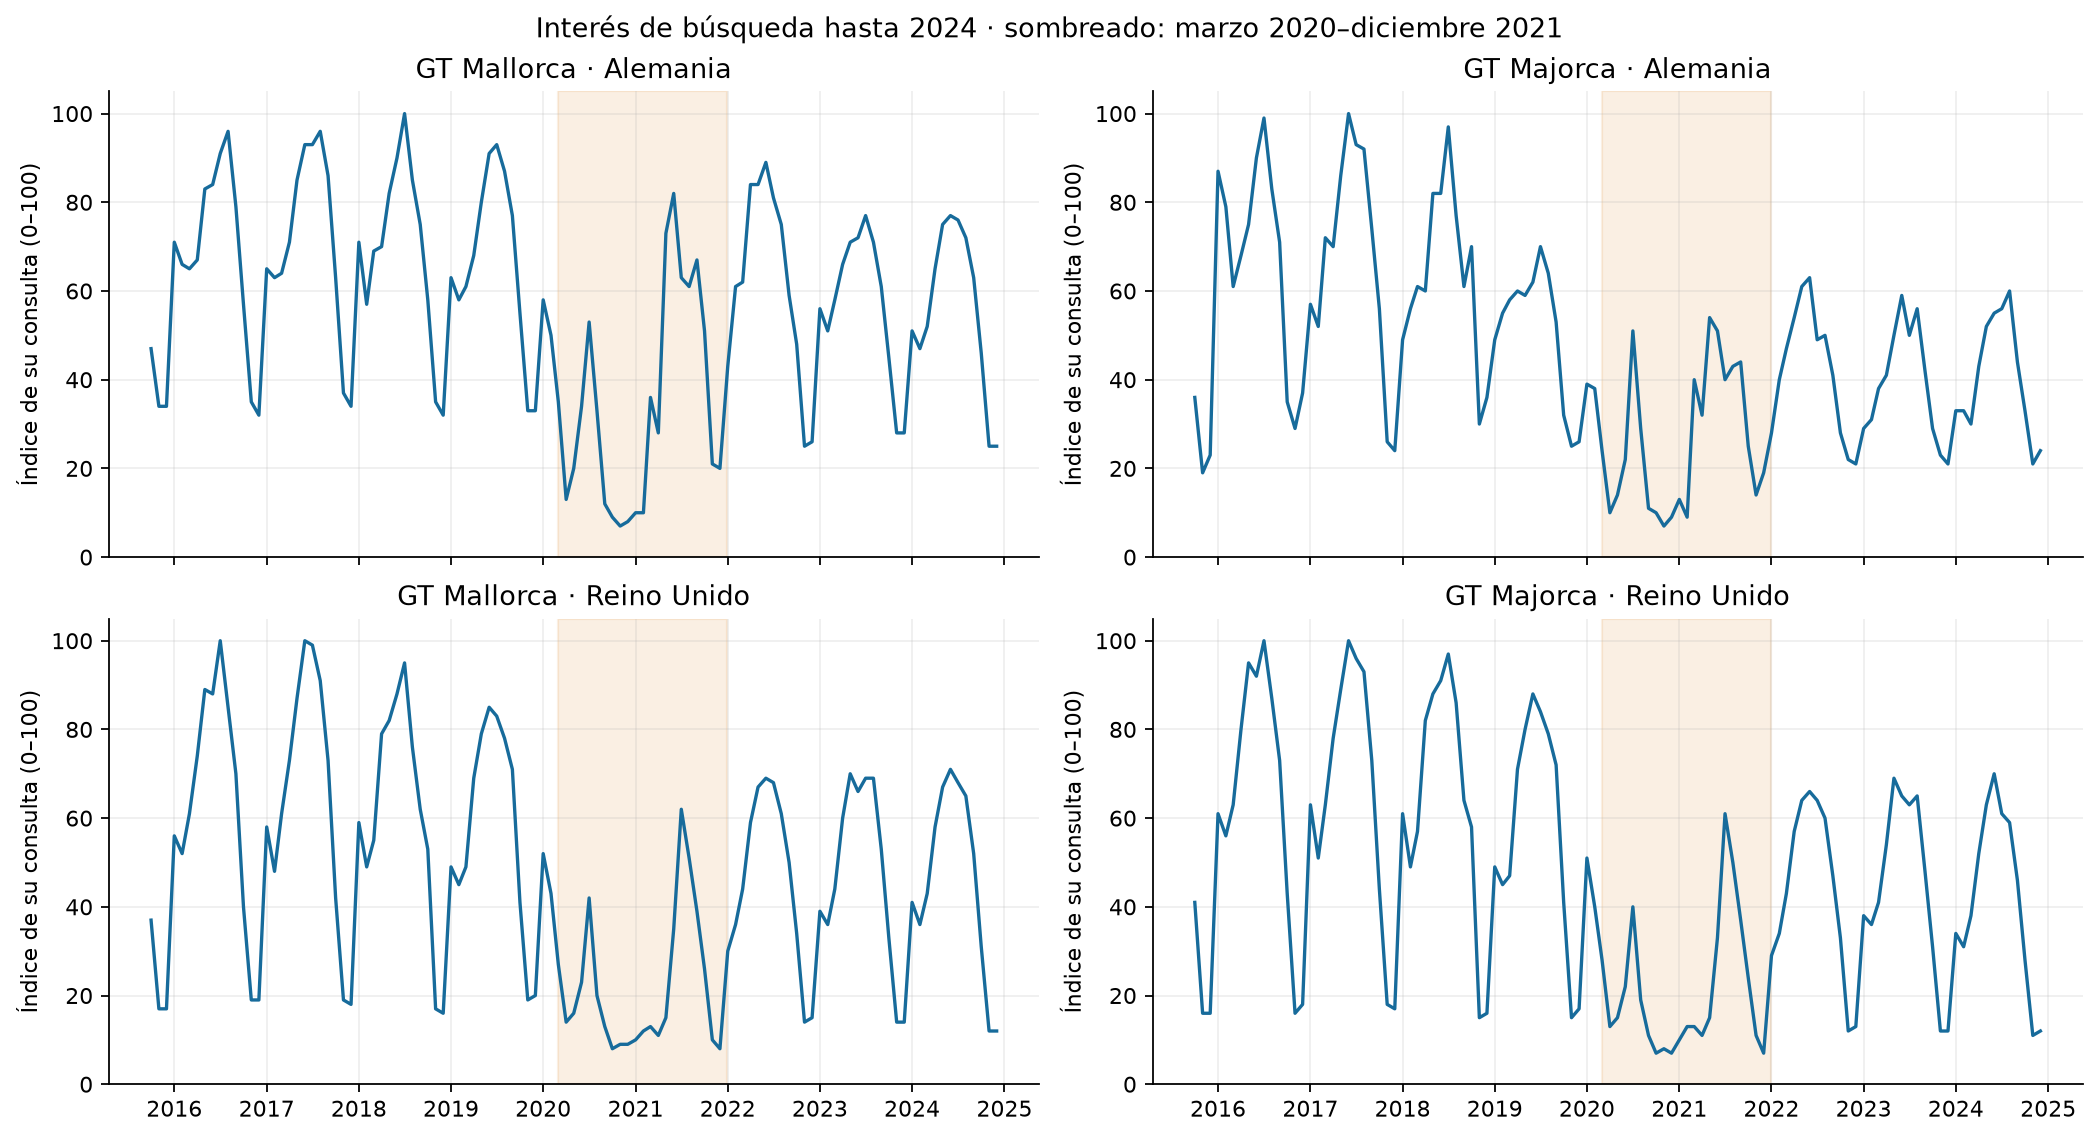

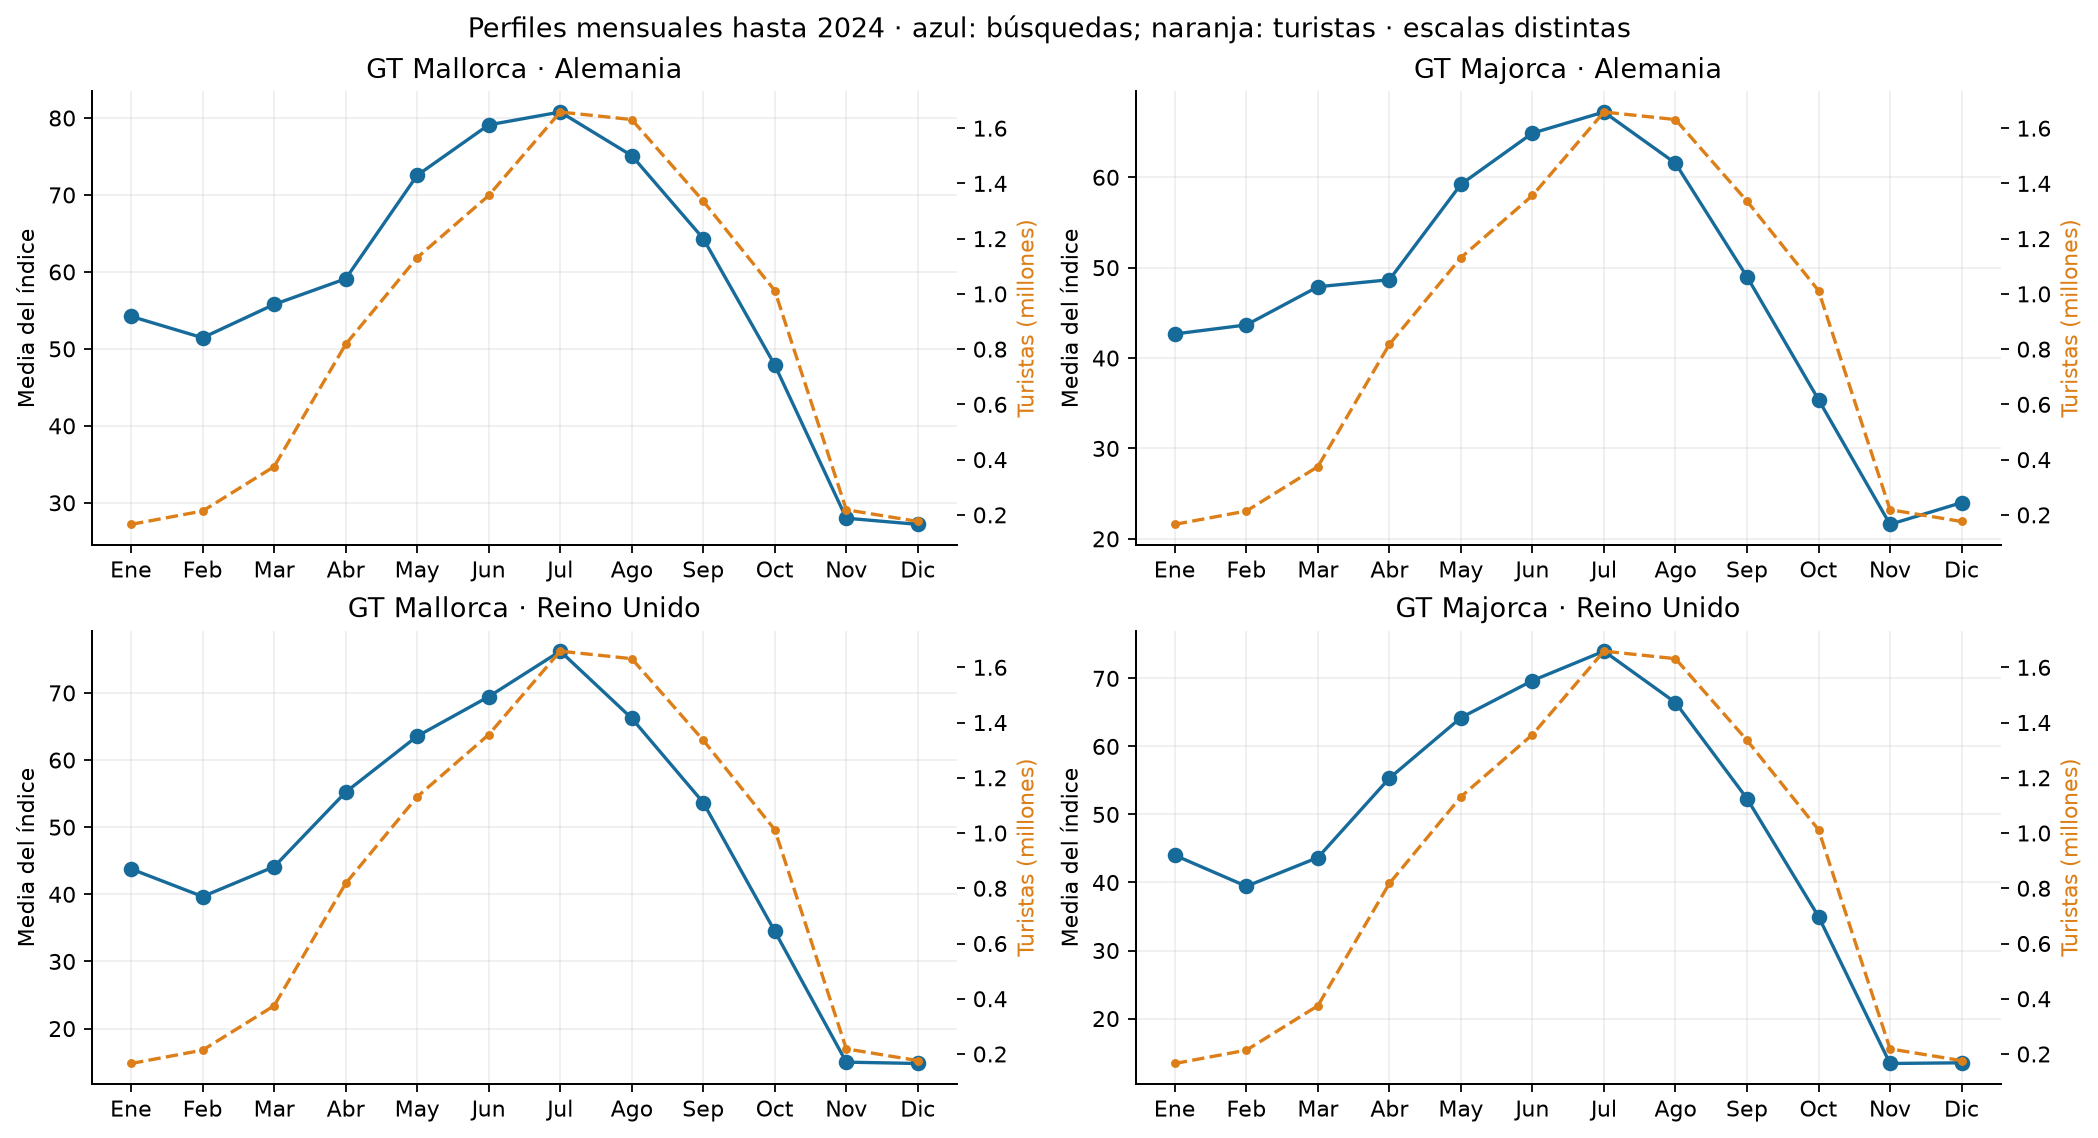

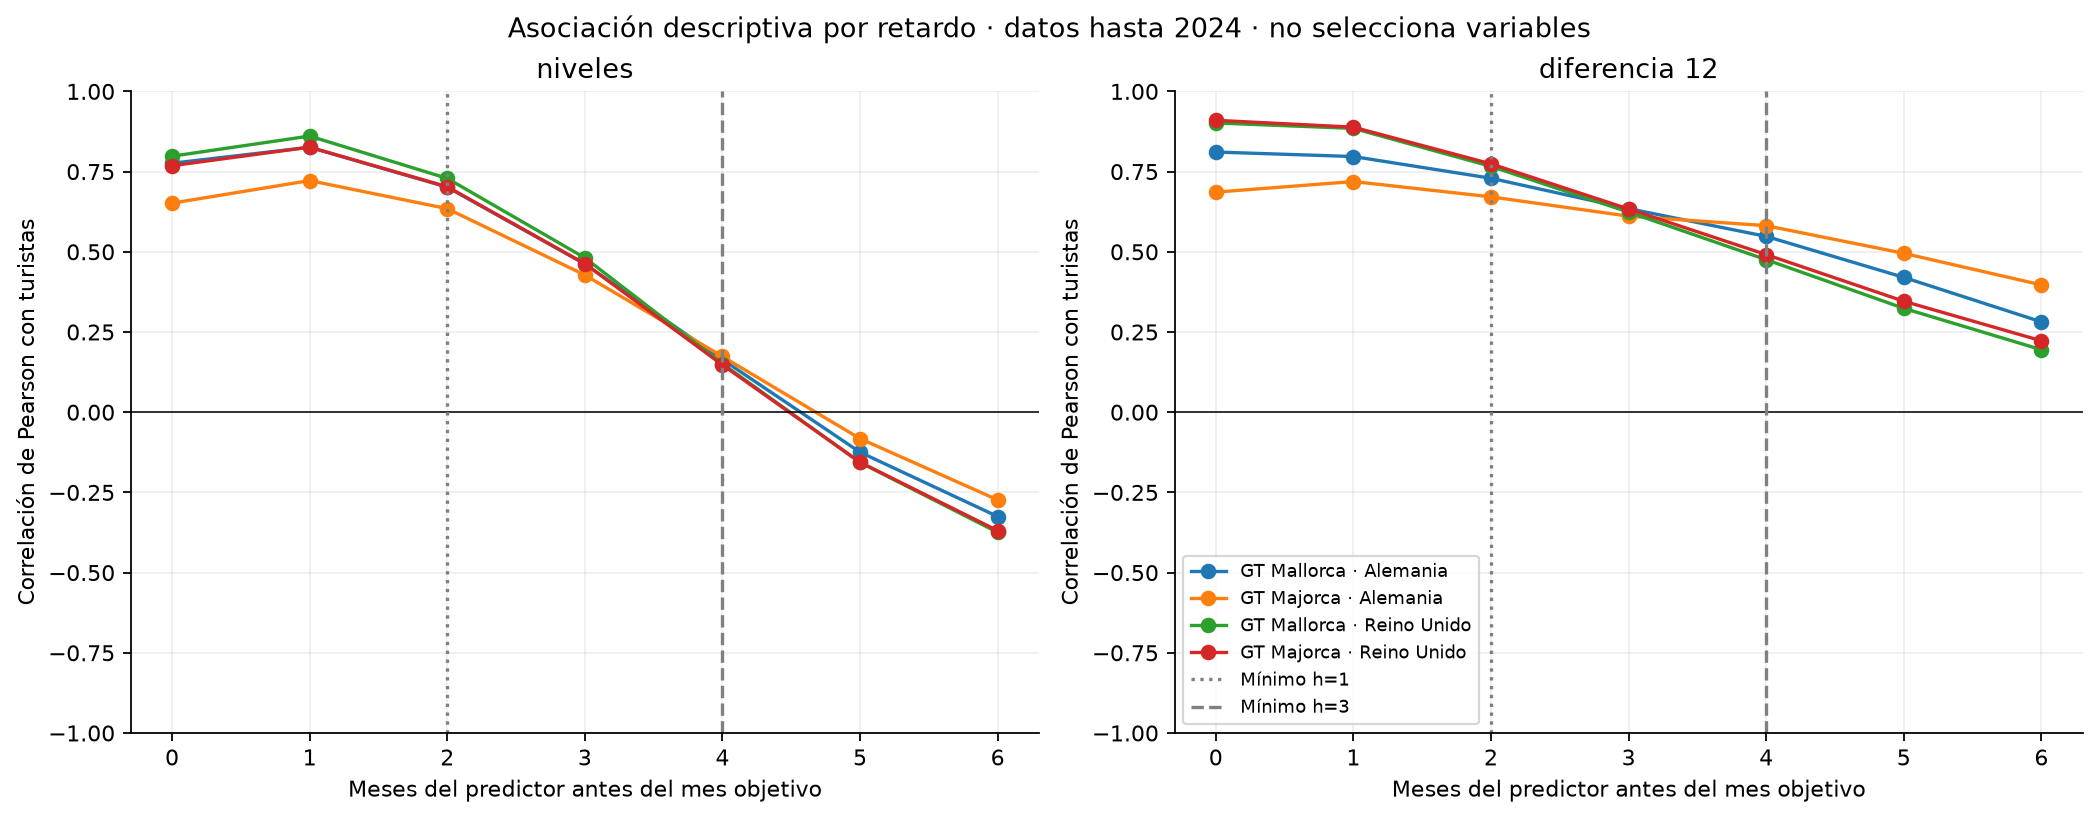

,count,mean,std,min,25%,50%,75%,max,ceros_hasta_2024
gt_mallorca_alemania,111.0,57.32,23.79,7.0,35.0,61.0,75.0,100.0,0
gt_majorca_alemania,111.0,46.60,22.76,7.0,29.0,44.0,60.5,100.0,0
gt_mallorca_reino_unido,111.0,47.30,26.09,8.0,19.5,49.0,68.5,100.0,0
gt_majorca_reino_unido,111.0,46.86,27.12,7.0,18.0,47.0,64.5,100.0,0


,variable,retardo_respecto_objetivo,transformacion,pearson,pares,admisible_h1_regla_base,admisible_h3_regla_base
0,gt_mallorca_alemania,0,niveles,0.776,111,False,False
1,gt_mallorca_alemania,0,diferencia_12,0.811,99,False,False
4,gt_mallorca_alemania,2,niveles,0.701,111,True,False
5,gt_mallorca_alemania,2,diferencia_12,0.729,99,True,False
8,gt_mallorca_alemania,4,niveles,0.164,111,True,True
9,gt_mallorca_alemania,4,diferencia_12,0.548,99,True,True
14,gt_majorca_alemania,0,niveles,0.652,111,False,False
15,gt_majorca_alemania,0,diferencia_12,0.686,99,False,False
18,gt_majorca_alemania,2,niveles,0.635,111,True,False
19,gt_majorca_alemania,2,diferencia_12,0.671,99,True,False


,gt_mallorca_alemania,gt_majorca_alemania,gt_mallorca_reino_unido,gt_majorca_reino_unido
gt_mallorca_alemania,1.000,0.896,0.930,0.921
gt_majorca_alemania,0.896,1.000,0.899,0.914
gt_mallorca_reino_unido,0.930,0.899,1.000,0.994
gt_majorca_reino_unido,0.921,0.914,0.994,1.000


**Lectura: Alemania.** Las dos grafías tienen correlación **0.896** en niveles hasta 2024. La coincidencia sugiere revisar redundancia, pero no determina cuál ofrece mejores pronósticos.

**Lectura: Reino Unido.** Las dos grafías tienen correlación **0.994** en niveles hasta 2024. La coincidencia sugiere revisar redundancia, pero no determina cuál ofrece mejores pronósticos.

**Lectura de los retardos admisibles.** En niveles, las correlaciones con dos meses de retardo van de **0.635 a 0.729**; con cuatro meses, de **0.147 a 0.174**. La reducción puede estar ligada al desfase estacional. Las diferencias interanuales aportan otra perspectiva, pero estas asociaciones no prueban una mejora incremental frente al histórico, calendario y otras variables externas.

Ampliación completada: tres figuras y cuatro tablas de Google Trends; sin imputación ni modelos.


In [21]:
gt_summary = eda_train[GT_COLUMNS].describe().T
gt_summary["ceros_hasta_2024"] = eda_train[GT_COLUMNS].eq(0).sum()
gt_summary.to_csv(EDA_DIR / "google_trends_descriptivos.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, constrained_layout=True)
for ax, column in zip(axes.flat, GT_COLUMNS):
    ax.plot(eda_train.index, eda_train[column], color="#176b9b", lw=1.5)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="#dd7f19", alpha=.12)
    ax.set(title=LABELS[column], ylabel="Índice de su consulta (0–100)", ylim=(0, 105))
fig.suptitle("Interés de búsqueda hasta 2024 · sombreado: marzo 2020–diciembre 2021")
save_show(fig, "07_google_trends_evolucion.png")

gt_profiles = eda_train[["turistas", *GT_COLUMNS]].groupby(eda_train.index.month).mean()
gt_profiles.index.name = "mes"
gt_profiles.to_csv(EDA_DIR / "google_trends_perfiles_mensuales.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
for ax, column in zip(axes.flat, GT_COLUMNS):
    ax.plot(gt_profiles.index, gt_profiles[column], color="#176b9b", marker="o")
    right = ax.twinx()
    right.plot(gt_profiles.index, gt_profiles["turistas"] / 1e6, color="#dd7f19", ls="--", marker=".")
    right.grid(False)
    right.set_ylabel("Turistas (millones)", color="#dd7f19")
    ax.set(title=LABELS[column], ylabel="Media del índice", xticks=range(1, 13), xticklabels=MONTHS)
fig.suptitle("Perfiles mensuales hasta 2024 · azul: búsquedas; naranja: turistas · escalas distintas")
save_show(fig, "08_google_trends_estacionalidad.png")

gt_lag_rows = []
for column in GT_COLUMNS:
    for lag in range(7):
        for transform in ["niveles", "diferencia_12"]:
            y = eda_train["turistas"]
            x = google_trends[column].loc[:"2024-12-01"]
            if transform == "diferencia_12":
                y, x = y.diff(12), x.diff(12)
            pair = pd.concat([y.rename("y"), x.shift(lag).reindex(y.index).rename("x")], axis=1).dropna()
            gt_lag_rows.append({"variable": column, "retardo_respecto_objetivo": lag,
                "transformacion": transform, "pearson": pair["y"].corr(pair["x"]), "pares": len(pair),
                "admisible_h1_regla_base": lag >= 2, "admisible_h3_regla_base": lag >= 4})
gt_lag_corr = pd.DataFrame(gt_lag_rows)
gt_lag_corr.to_csv(EDA_DIR / "google_trends_correlaciones_retardos.csv", index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, transform in zip(axes, ["niveles", "diferencia_12"]):
    for column in GT_COLUMNS:
        subset = gt_lag_corr.loc[gt_lag_corr["variable"].eq(column) & gt_lag_corr["transformacion"].eq(transform)]
        ax.plot(subset["retardo_respecto_objetivo"], subset["pearson"], marker="o", label=LABELS[column])
    ax.axhline(0, color="black", lw=.7)
    ax.axvline(2, color="gray", ls=":", label="Mínimo h=1")
    ax.axvline(4, color="gray", ls="--", label="Mínimo h=3")
    ax.set(title=transform.replace("_", " "), xlabel="Meses del predictor antes del mes objetivo",
           ylabel="Correlación de Pearson con turistas", ylim=(-1, 1), xticks=range(7))
axes[1].legend(fontsize=8, loc="lower left")
fig.suptitle("Asociación descriptiva por retardo · datos hasta 2024 · no selecciona variables")
save_show(fig, "09_google_trends_retardos.png")
display(gt_summary.round(2))
display(gt_lag_corr.loc[gt_lag_corr["retardo_respecto_objetivo"].isin([0, 2, 4])].round(3))
gt_redundancy = eda_train[GT_COLUMNS].corr()
gt_redundancy.to_csv(EDA_DIR / "google_trends_correlaciones_entre_indices.csv", encoding="utf-8-sig")
display(gt_redundancy.round(3))
for country, columns in [("Alemania", ["gt_mallorca_alemania", "gt_majorca_alemania"]),
                         ("Reino Unido", ["gt_mallorca_reino_unido", "gt_majorca_reino_unido"])]:
    r = gt_redundancy.loc[columns[0], columns[1]]
    display(Markdown(f"**Lectura: {country}.** Las dos grafías tienen correlación **{r:.3f}** en niveles hasta 2024. La coincidencia sugiere revisar redundancia, pero no determina cuál ofrece mejores pronósticos."))
r_h1 = gt_lag_corr.loc[gt_lag_corr["retardo_respecto_objetivo"].eq(2) & gt_lag_corr["transformacion"].eq("niveles"), "pearson"]
r_h3 = gt_lag_corr.loc[gt_lag_corr["retardo_respecto_objetivo"].eq(4) & gt_lag_corr["transformacion"].eq("niveles"), "pearson"]
display(Markdown(f"**Lectura de los retardos admisibles.** En niveles, las correlaciones con dos meses de retardo van de **{r_h1.min():.3f} a {r_h1.max():.3f}**; con cuatro meses, de **{r_h3.min():.3f} a {r_h3.max():.3f}**. La reducción puede estar ligada al desfase estacional. Las diferencias interanuales aportan otra perspectiva, pero estas asociaciones no prueban una mejora incremental frente al histórico, calendario y otras variables externas."))
eda_metadata.update({"google_trends": {"candidatos": GT_COLUMNS, "retardos_explorados": list(range(7)),
                    "seleccion": "pendiente de validacion temporal", "versiones_por_origen": "no reconstruidas"},
                    "figuras": figures})
(EDA_DIR / "ejecucion.json").write_text(json.dumps(eda_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
assert eda[VALUE_COLUMNS].equals(master[VALUE_COLUMNS])
print("Ampliación completada: tres figuras y cuatro tablas de Google Trends; sin imputación ni modelos.")

## 24. Conclusiones de la incorporación de Google Trends

1. **Cobertura:** cuatro series mensuales de enero de 2015 a diciembre de 2025. El ETL conserva 123 meses comunes y genera una extracción auxiliar de 132 meses, útil para disponer de contexto anterior al inicio del maestro.
2. **Interpretación:** se conserva cada índice con su escala original. No se suman consultas ni se interpretan los niveles como volumen absoluto o como proporción de turistas alemanes y británicos.
3. **Selección pendiente:** las correlaciones y los perfiles orientan hipótesis. Se contrastará la aportación incremental de Google Trends frente a los mismos modelos sin ese grupo, con iguales orígenes, horizontes y tratamiento de ausentes. Se evitará introducir cuatro señales redundantes sin evaluarlas.
4. **Disponibilidad:** regla base t−1 y sensibilidad t−2 desde el origen. Esto equivale a retardos mínimos 2/4 y 3/5 respecto a los objetivos h=1/h=3. No se confunden los retardos de una covariable con el horizonte de pronóstico.
5. **Trazabilidad pendiente:** los archivos acreditan categoría, término y país. Falta confirmar fecha de descarga, tipo de búsqueda, selección de término o tema y URL de consulta. El catálogo deja esos campos vacíos.
6. **Límite de la evaluación:** descarga retrospectiva con normalización del periodo completo y sin versiones históricas. Las asociaciones hasta 2024 no consultan filas de 2025, pero heredan esa construcción de la fuente. Este experimento no podrá describirse como una reconstrucción exacta de predicción en tiempo real.

Las fuentes originales permanecen intactas. No se han ajustado modelos, imputado valores ni modificado la memoria.

## 25. Variables de predicción por horizonte

Se construyen entradas para emitir pronósticos al cierre de cada mes `t`, con objetivos en `t+1` y `t+3`. El índice identifica el mes de origen; `fecha_corte` identifica su cierre. Los valores del mes objetivo se exportan únicamente como etiquetas y nunca como predictores. La fecha de cada variable se comprueba frente a la política del apartado 19, incluyendo publicaciones excepcionalmente tardías cuando exista evidencia.

| Familia | Construcción respecto al origen t, regla base | Uso |
|---|---|---|
| Histórico de turistas | Valores en t−2, t−3, t−4, t−5, t−8 y t−14 | Último dato publicado y retardos adicionales 1, 2, 3, 6 y 12 |
| Resúmenes del objetivo | Medias de 3, 6 y 12 meses que terminan en t−2 | Nivel reciente; ventanas completas, sin saltar ausentes |
| Referencia estacional | Turistas de t+h−12 | Mismo mes del año anterior al objetivo; disponibilidad comprobada |
| Calendario del objetivo | Mes, seno/coseno anual y meses desde enero de 2015 | Información conocida; índice temporal fijo, sin estimación con la muestra |
| Aeropuerto, hoteles y Google Trends | Valores en t−1, t−2 y t−13 | Último dato permitido y retardos adicionales 1 y 12 |

Los nombres `*_origen_lagN` expresan meses anteriores al origen, no al objetivo: su retardo respecto al objetivo es `N+h`. Las medias se identifican por su ventana y su último mes. La referencia estacional tiene retardo 12 respecto al objetivo y, por tanto, retardo 11 respecto al origen para h=1 y 9 para h=3. La versión de sensibilidad añade un mes de espera a todos los grupos; la referencia estacional sigue usando el mismo mes del año anterior si está publicado.

Este catálogo contiene **candidatos**, no una selección definitiva. Con una muestra mensual corta no se introducirán todas las columnas por defecto. Se separan los grupos histórico/calendario, aeropuerto/hoteles y búsquedas para evaluar su aportación en validación anterior a 2025. La referencia estacional también permite construir Seasonal Naïve. Estas matrices son entradas directas por horizonte para ML; SARIMA/SARIMAX necesitan su propia preparación secuencial y no pueden recibir realizaciones futuras de las exógenas.

### Ausentes, calidad y límites

Se conserva el calendario de 123 orígenes, incluso donde falta historia o todavía no existe etiqueta. Los ceros se mantienen; no se realiza imputación, escalado ni selección de variables. Si una ventana contiene un ausente o un dato no publicado, su media queda ausente. La auditoría distingue falta de contexto, bloqueo por publicación y ausencia en la fuente. Las marcas `U`, `P` y provisionales se conservan en la auditoría y no se convierten en números para el modelo. La historia incompleta se identifica por fila, sin eliminar meses del maestro.

Las etiquetas incorporan su fecha operativa de publicación. El bloque de entrenamiento de un origen debe limitarse a etiquetas difundidas antes de su cierre, y 2025 permanece excluido de la selección. La función `training_rows_at` aplica ambos límites; no define todavía los folds de validación. La pertenencia a 2025 depende del **mes objetivo**, aunque el origen esté en 2024. Los objetivos posteriores al final del maestro quedan sin etiqueta y no son evaluables.

La política utiliza fechas supuestas cuando no se dispone de una fecha efectiva. Google Trends mantiene su espera operativa supuesta y su normalización retrospectiva. No se reconstruyen primeras versiones históricas ni se incorpora meteorología pendiente.


In [22]:
FEATURE_DIR = PROJECT_ROOT / "outputs" / "predictores"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

def feature_specifications(horizon, extra_wait=0):
    specs = []
    def add(name, group, variable, lags, operation="valor"):
        specs.append({"predictor": name, "grupo": group, "variable": variable,
                      "retardos_origen": list(lags), "operacion": operation})
    wait = PUBLICATION_DELAYS["turistas"] + extra_wait
    for offset in [0, 1, 2, 3, 6, 12]:
        lag = wait + offset
        add(f"turistas_origen_lag{lag}", "turistas", "turistas", [lag])
    for window in [3, 6, 12]:
        add(f"turistas_media{window}_hasta_lag{wait}", "turistas", "turistas",
            range(wait, wait + window), "media")
    add("turistas_mismo_mes_ano_anterior", "turistas", "turistas", [12-horizon])
    for group, variables in GROUP_VARIABLES.items():
        if group == "turistas":
            continue
        for variable in variables:
            for offset in [0, 1, 12]:
                lag = PUBLICATION_DELAYS[group] + extra_wait + offset
                add(f"{variable}_origen_lag{lag}", group, variable, [lag])
    return specs

def publication_date(group, reference, extra_wait=0, dates=None):
    # Mantener el cierre conservador, incluso si la nota se publicó antes.
    planned = (reference + PUBLICATION_DELAYS[group] + extra_wait).end_time.normalize()
    actual = (dates or {}).get((group, reference.start_time))
    if actual is not None:
        actual = (pd.Timestamp(actual).to_period("M") + extra_wait).end_time.normalize()
        planned = max(planned, actual)
    return planned

def build_prediction_features(data, horizon, extra_wait=0, dates=None):
    assert horizon in [1, 3] and extra_wait in [0, 1]
    assert data.index.equals(pd.date_range(data.index.min(), data.index.max(), freq="MS"))
    specs = feature_specifications(horizon, extra_wait)
    periods = data.index.to_period("M")
    features = pd.DataFrame(index=data.index)
    features.index.name = "mes_origen"
    audit_rows, contexts = [], []
    for spec in specs:
        values, context = [], []
        group, variable = spec["grupo"], spec["variable"]
        state_column = "aena_estado" if group == "aena" else variable + "_estado"
        for origin in periods:
            cutoff = origin.end_time.normalize()
            refs = [origin - lag for lag in spec["retardos_origen"]]
            dates_used = [publication_date(group, ref, extra_wait, dates) for ref in refs]
            in_range = [ref.start_time in data.index for ref in refs]
            allowed = [release <= cutoff for release in dates_used]
            raw = [data.at[ref.start_time, variable] if exists else np.nan
                   for ref, exists in zip(refs, in_range)]
            usable = [value if ok else np.nan for value, ok in zip(raw, allowed)]
            value = float(np.mean(usable)) if all(pd.notna(v) for v in usable) else np.nan
            values.append(value)
            context.append(all(in_range))
            states = [str(data.at[ref.start_time, state_column]) for ref, exists in zip(refs, in_range)
                      if exists and state_column in data]
            audit_rows.append({"mes_origen": origin.start_time, "horizonte": horizon,
                "espera_adicional": extra_wait, "predictor": spec["predictor"], "grupo": group,
                "fecha_corte": cutoff, "primer_mes_referencia": min(refs).start_time,
                "ultimo_mes_referencia": max(refs).start_time,
                "ultima_fecha_operativa": max(dates_used), "contexto_completo": all(in_range),
                "publicacion_permitida": all(allowed),
                "ausentes_fuente": sum(exists and pd.isna(v) for exists, v in zip(in_range, raw)),
                "valor_disponible": pd.notna(value), "estados_fuente": "|".join(sorted(set(states)))})
        features[spec["predictor"]] = values
        contexts.append(context)
    target_periods = periods + horizon
    features["mes_objetivo"] = target_periods.month.astype(float)
    features["mes_sin"] = np.sin(2*np.pi*target_periods.month/12)
    features["mes_cos"] = np.cos(2*np.pi*target_periods.month/12)
    features["tiempo_meses_desde_2015_01"] = (target_periods.year-2015)*12 + target_periods.month-1
    metadata = pd.DataFrame(index=data.index)
    metadata.index.name = "mes_origen"
    metadata["fecha_corte"] = periods.end_time.normalize()
    metadata["mes_objetivo"] = target_periods.start_time
    metadata["turistas_objetivo"] = data["turistas"].reindex(target_periods.start_time).to_numpy()
    metadata["estado_objetivo"] = data["turistas_estado"].reindex(target_periods.start_time).to_numpy()
    metadata["fecha_publicacion_objetivo"] = [publication_date("turistas", p, extra_wait, dates)
                                              for p in target_periods]
    metadata["contexto_completo"] = np.asarray(contexts).all(axis=0)
    metadata["etiqueta_observada"] = metadata["turistas_objetivo"].notna()
    metadata["uso_por_mes_objetivo"] = np.where(target_periods.year <= 2024, "train_valid",
        np.where(target_periods.year == 2025, "prueba_2025", "fuera_periodo"))
    catalog = pd.DataFrame([{**s, "horizonte": horizon, "espera_adicional": extra_wait,
        "retardos_objetivo": [lag+horizon for lag in s["retardos_origen"]]} for s in specs])
    calendar_catalog = pd.DataFrame([{"predictor": c, "grupo": "calendario", "variable": c,
        "retardos_origen": [], "retardos_objetivo": [], "operacion": "calendario_conocido",
        "horizonte": horizon, "espera_adicional": extra_wait}
        for c in features.columns if c not in set(catalog["predictor"])])
    catalog = pd.concat([catalog, calendar_catalog], ignore_index=True)
    return features, metadata, pd.DataFrame(audit_rows), catalog

def training_rows_at(metadata, forecast_origin):
    """Etiquetas publicadas y anteriores a 2025; la selección de folds es posterior."""
    cutoff = pd.Timestamp(forecast_origin).to_period("M").end_time.normalize()
    return (metadata["contexto_completo"] & metadata["etiqueta_observada"]
            & metadata["fecha_publicacion_objetivo"].le(cutoff)
            & metadata["uso_por_mes_objetivo"].eq("train_valid"))

prediction_sets, feature_audits, feature_catalogs, feature_summaries = {}, [], [], []
for extra_wait, scenario in [(0, "base"), (1, "espera_adicional")]:
    for horizon in [1, 3]:
        X, meta, audit, catalog = build_prediction_features(master, horizon, extra_wait, verified_dates)
        prediction_sets[(scenario, horizon)] = (X, meta)
        X.to_csv(FEATURE_DIR / f"X_{scenario}_h{horizon}.csv", encoding="utf-8-sig")
        meta.to_csv(FEATURE_DIR / f"etiquetas_{scenario}_h{horizon}.csv", encoding="utf-8-sig")
        feature_audits.append(audit)
        feature_catalogs.append(catalog)
        for usage in ["train_valid", "prueba_2025", "fuera_periodo"]:
            selected = meta["uso_por_mes_objetivo"].eq(usage)
            feature_summaries.append({"escenario": scenario, "horizonte": horizon, "uso": usage,
                "origenes": int(selected.sum()), "predictores": len(X.columns),
                "con_historia_y_etiqueta": int((selected & meta["contexto_completo"] & meta["etiqueta_observada"]).sum()),
                "con_todas_las_entradas": int((selected & meta["etiqueta_observada"] & X.notna().all(axis=1)).sum())})
feature_audit = pd.concat(feature_audits, ignore_index=True)
feature_catalog = pd.concat(feature_catalogs, ignore_index=True)
feature_summary = pd.DataFrame(feature_summaries)
feature_audit.to_csv(FEATURE_DIR / "auditoria_predictores.csv", index=False, encoding="utf-8-sig")
feature_catalog.to_csv(FEATURE_DIR / "catalogo_predictores.csv", index=False, encoding="utf-8-sig")
feature_summary.to_csv(FEATURE_DIR / "resumen_construccion.csv", index=False, encoding="utf-8-sig")
display(feature_summary)
display(prediction_sets[("base", 1)][0].loc[["2024-12-01"]])


,escenario,horizonte,uso,origenes,predictores,con_historia_y_etiqueta,con_todas_las_entradas
0,base,1,train_valid,110,50,96,88
1,base,1,prueba_2025,12,50,12,12
2,base,1,fuera_periodo,1,50,0,0
3,base,3,train_valid,108,50,94,86
4,base,3,prueba_2025,12,50,12,12
5,base,3,fuera_periodo,3,50,0,0
6,espera_adicional,1,train_valid,110,50,95,87
7,espera_adicional,1,prueba_2025,12,50,12,12
8,espera_adicional,1,fuera_periodo,1,50,0,0
9,espera_adicional,3,train_valid,108,50,93,85


,turistas_origen_lag2,turistas_origen_lag3,turistas_origen_lag4,turistas_origen_lag5,turistas_origen_lag8,turistas_origen_lag14,turistas_media3_hasta_lag2,turistas_media6_hasta_lag2,turistas_media12_hasta_lag2,turistas_mismo_mes_ano_anterior,...,gt_mallorca_reino_unido_origen_lag1,gt_mallorca_reino_unido_origen_lag2,gt_mallorca_reino_unido_origen_lag13,gt_majorca_reino_unido_origen_lag1,gt_majorca_reino_unido_origen_lag2,gt_majorca_reino_unido_origen_lag13,mes_objetivo,mes_sin,mes_cos,tiempo_meses_desde_2015_01
mes_origen,,,,,,,,,,,,,,,,,,,,,
2024-12-01,1429437.0,1708730.0,2002816.0,2005430.0,1204359.0,1247236.0,1713661.0,1.759625e+06,1.111348e+06,220848.0,...,12.0,31.0,14.0,11.0,28.0,12.0,1.0,0.5,0.866025,120


## 26. Comprobaciones temporales y resultado

Los controles contrastan valores con sus meses de referencia, recalculan medias, comprueban etiquetas y disponibilidad de entrenamiento y simulan una difusión hotelera tardía. También alteran datos todavía no publicados en un origen para verificar que no cambian sus entradas. La auditoría y el catálogo se guardan en `outputs/predictores/`, junto con cuatro matrices numéricas y sus etiquetas separadas. Las filas futuras sin etiqueta se conservan identificadas; no se contabilizan como resultados de prueba.


In [23]:
for (scenario, horizon), (X, meta) in prediction_sets.items():
    wait = 0 if scenario == "base" else 1
    assert len(X) == len(master) and X.index.equals(meta.index)
    assert not X.columns.duplicated().any()
    assert "turistas_objetivo" not in X and "estado_objetivo" not in X
    pd.testing.assert_series_equal(X[f"turistas_origen_lag{2+wait}"], master["turistas"].shift(2+wait), check_names=False)
    pd.testing.assert_series_equal(X[f"turistas_media3_hasta_lag{2+wait}"], master["turistas"].shift(2+wait).rolling(3, min_periods=3).mean(), check_names=False)
    pd.testing.assert_series_equal(X["turistas_mismo_mes_ano_anterior"], master["turistas"].shift(12-horizon), check_names=False)
    assert meta.loc["2024-12-01", "mes_objetivo"] == pd.Timestamp("2025-01-01" if horizon == 1 else "2025-03-01")
    mask = training_rows_at(meta, "2024-12-01")
    assert meta.loc[mask, "mes_objetivo"].max() == pd.Timestamp("2024-10-01")-pd.DateOffset(months=wait)
    assert meta.loc[mask, "fecha_publicacion_objetivo"].le(pd.Timestamp("2024-12-31")).all()
    assert not training_rows_at(meta, "2025-12-01")[meta["uso_por_mes_objetivo"].eq("prueba_2025")].any()
    # Perturbar meses existentes pero todavía no difundidos al cierre de diciembre.
    altered = master.copy(deep=True)
    origin = pd.Timestamp("2024-12-01")
    for group, variables in GROUP_VARIABLES.items():
        last_known = origin - pd.DateOffset(months=PUBLICATION_DELAYS[group]+wait)
        altered.loc[altered.index > last_known, variables] = 99999999
    changed_X, _, _, _ = build_prediction_features(altered, horizon, wait, verified_dates)
    pd.testing.assert_series_equal(X.loc[origin], changed_X.loc[origin])

X1, labels1 = prediction_sets[("base", 1)]
assert X1.loc["2020-06-01", "turistas_origen_lag2"] == 0
assert labels1.loc["2020-03-01", "turistas_objetivo"] == 0
assert labels1.loc["2020-03-01", "estado_objetivo"] == "U"
assert pd.isna(X1.loc["2020-06-01", "viajeros_hoteles_origen_lag1"])
assert pd.isna(X1.loc["2020-06-01", "estancia_media_noches_origen_lag1"])
late_dates = {**verified_dates, ("hoteles", pd.Timestamp("2024-11-01")): pd.Timestamp("2025-01-02")}
late_X, _, late_audit, _ = build_prediction_features(master, 1, dates=late_dates)
assert pd.isna(late_X.loc["2024-12-01", "viajeros_hoteles_origen_lag1"])
assert not late_audit.loc[late_audit.mes_origen.eq(pd.Timestamp("2024-12-01")) & late_audit.predictor.eq("viajeros_hoteles_origen_lag1"), "publicacion_permitida"].item()
assert feature_audit.loc[feature_audit.valor_disponible, "publicacion_permitida"].all()

feature_manifest = {"fecha_documentacion": "2026-10-09", "horizontes": [1, 3],
    "escenarios": ["base", "espera_adicional"], "origenes_por_matriz": len(master),
    "predictores_por_matriz": len(X1.columns), "imputacion": "pendiente, no realizada",
    "seleccion": "candidatos; pendiente de validacion anterior a 2025",
    "entrenamiento": "etiquetas publicadas al origen y mes objetivo anterior a 2025",
    "grupos": {scenario: {str(h): {group: cat.loc[cat.grupo.eq(group), "predictor"].tolist()
        for group in cat.grupo.unique()} for h in [1,3]
        for cat in [feature_catalog.loc[feature_catalog.horizonte.eq(h) & feature_catalog.espera_adicional.eq(wait)]]}
        for wait, scenario in [(0,"base"),(1,"espera_adicional")]},
    "politica_disponibilidad": availability_policy,
    "maestro_sha256": hashlib.sha256((OUTPUT_DIR / "dataset_maestro_mallorca.csv").read_bytes()).hexdigest(),
    "limite": "fuentes revisadas y Google Trends normalizado retrospectivamente; no reconstruye primeras versiones"}
(FEATURE_DIR / "construccion.json").write_text(json.dumps(feature_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Controles superados: cuatro matrices de {len(master)} orígenes y {len(X1.columns)} candidatos; etiquetas separadas.")
print("Ceros y ausentes conservados. Sin imputación ni ajuste de modelos. Salidas:", FEATURE_DIR)


Controles superados: cuatro matrices de 123 orígenes y 50 candidatos; etiquetas separadas.
Ceros y ausentes conservados. Sin imputación ni ajuste de modelos. Salidas: C:\Users\acort\Documents\Codex\tfm-turismo-mallorca\outputs\predictores


## 27. Protocolo de evaluación temporal

**Decisión fijada el 9 de octubre de 2026, antes de ajustar modelos.** Se utiliza evaluación con origen móvil mensual y ventana de entrenamiento expansiva. El horizonte se mide desde el cierre del mes de origen: h=1 pronostica el mes siguiente y h=3 exclusivamente el tercer mes siguiente, no el promedio de los pasos 1–3. La separación se realiza por **mes objetivo**, no por año del origen.

| Bloque | Meses objetivo | Función |
|---|---|---|
| Historia inicial | Octubre de 2015–2019, según publicación en cada origen | Contexto y primeros entrenamientos |
| Validación para selección | Enero de 2020–julio de 2024: 55 objetivos por horizonte | Elegir configuraciones, grupos de variables y tratamiento de ausentes |
| Validación complementaria | Agosto–diciembre de 2024: 5 objetivos por horizonte | Diagnóstico con configuración fija; no cambiar la selección |
| Prueba final | Enero–diciembre de 2025: 12 objetivos por horizonte | Evaluar la configuración elegida sin modificarla por sus resultados |

Los 60 meses de validación se resumen en cinco bloques anuales, distinguiendo selección y diagnóstico, pero **cada mes tiene su propio entrenamiento**, limitado por lo que ya estaría publicado. No se entrenará una sola vez al inicio del año ni se utilizarán folds aleatorios. Los resultados de 2020–2021 se informarán aparte de los de 2022–2024. El bloque final es una simulación retrospectiva de doce emisiones mensuales, no una predicción de todo 2025 realizada en diciembre de 2024.

### Información equivalente y entrenamiento disponible

Los cuatro escenarios (h=1/h=3, espera base/adicional) evalúan los mismos 72 meses objetivo, de 2020 a 2025. Sus orígenes difieren por horizonte: enero de 2025 se emite desde diciembre de 2024 para h=1 y desde octubre de 2024 para h=3. En un mismo origen, los modelos comparten el calendario, el límite de publicación y las fuentes autorizadas. Esto no obliga a algoritmos distintos a consumir las mismas columnas.

En la regla base, al cierre de t las etiquetas del objetivo deben referirse como máximo a t−2; con espera adicional, a t−3. Las filas supervisadas admitidas tienen objetivo desde abril de 2017, contexto completo y etiqueta publicada. Este comienzo común cubre la pérdida de historia del catálogo en ambos horizontes y esperas. Se exige un mínimo operativo de 24 filas supervisadas; es una salvaguarda inicial, no una garantía de tamaño suficiente para ML.

SARIMA/SARIMAX podrán usar la secuencia del objetivo desde octubre de 2015 hasta el último mes autorizado; ML pierde las etiquetas iniciales necesarias para construir sus retardos. Se registrarán ambos tamaños: equivalencia de información no implica idéntico número de observaciones de estimación. Para SARIMA, alcanzar t+1 desde t−2 requiere tres pasos internos; alcanzar t+3 requiere cinco. Seasonal Naïve consulta el mismo mes del año anterior al objetivo, previa comprobación de publicación.

Los meses anteriores de validación pueden entrar en entrenamientos posteriores cuando ya estén publicados: es la ventana expansiva. Ninguna etiqueta del mes pronosticado ni de sus meses posteriores se usa para estimar ese pronóstico. El control por fecha produce el intervalo de separación necesario entre filas supervisadas; no se sustituye por un `gap=1` arbitrario.

### Cierre de selección antes del primer origen de prueba

La configuración se congela, bajo la política de disponibilidad, al cierre del **31 de octubre de 2024**: es el primer origen de prueba para h=3 (enero de 2025). Para que los dos horizontes y ambas esperas sean comparables, la selección utiliza objetivos hasta **julio de 2024**, publicados como máximo en octubre con la espera adicional de tres meses del objetivo. Usar noviembre o diciembre de 2024 para elegir la configuración de ese primer pronóstico sería información futura, aunque esos meses no pertenezcan a 2025.

Agosto–diciembre de 2024 se puntuarán como diagnóstico retrospectivo con configuración fija. Algunos de sus orígenes preceden al cierre de selección: este diagnóstico no acredita que la configuración elegida estuviera disponible en esas fechas. Se calculará sin reajustar hiperparámetros, elegir columnas ni reglas de preparación por esos errores. Si ese diagnóstico motivara un rediseño, habría que declarar otro experimento y fijar una nueva prueba todavía no utilizada. El cierre aquí es una regla de la simulación retrospectiva; no acredita que los experimentos se ejecutaran realmente en octubre de 2024.

### Reserva de 2025 y actualización mensual

Hiperparámetros, elección de columnas, reglas de imputación y alternativas de preparación se decidirán con los 55 objetivos de validación para selección, hasta julio de 2024. Durante la prueba podrán reestimarse parámetros e imputadores usando únicamente etiquetas de hasta diciembre de 2024 que ya estén publicadas en ese origen, con la configuración elegida fija. Las etiquetas de 2025 se bloquean para ajuste y selección durante todo el año.

Los valores de 2025 ya publicados sí pueden alimentar retardos o actualizar el estado de un modelo secuencial **sin reestimar sus parámetros con esas etiquetas**. Esta actualización utiliza información disponible para emitir el pronóstico; debe distinguirse de incorporar 2025 al entrenamiento. Un experimento futuro que reentrene con etiquetas de 2025 tendría que registrarse aparte. El EDA ya ha examinado descriptivamente la cobertura y calidad de 2025; su reserva para evaluación no implica que el archivo nunca se haya visto.

### Comparaciones, ausentes y métricas

Se compararán Seasonal Naïve y SARIMA como referencias con histórico; SARIMAX, Random Forest y XGBoost según las fuentes que puedan utilizar. Los grupos de entradas son: histórico/calendario; esas entradas más aeropuerto/hoteles; y las anteriores más Google Trends. Para SARIMAX hay que construir exógenas conocidas en todos los pasos internos o pronosticarlas sin realizaciones futuras: la matriz directa de ML no resuelve ese requisito.

No se filtrará el calendario común según las columnas elegidas ni con un `dropna` global. Los ausentes de entradas se tratarán exclusivamente dentro del entrenamiento y con una regla fijada en validación. Si un modelo no genera un pronóstico, se registrará el fallo; no se ocultará reduciendo su denominador. Se publicará la cobertura y, si es necesaria una comparación por pares incompletos, se identificará el subconjunto común y su tamaño. Los ceros y las etiquetas `U` se conservan; podrá informarse un diagnóstico adicional sin las dos etiquetas de baja fiabilidad, identificado y sin alterar el resultado principal.

El criterio principal de selección será RMSE sobre los 55 pronósticos de validación para selección de cada horizonte; MAE será complementario. Se calcularán sobre errores en la escala original y se presentarán también por año y por periodo pandémico/posterior. El RMSE agregado se obtiene de todos los errores cuadrados, no promediando los RMSE anuales. No se promediarán h=1 y h=3 para declarar un ganador único. Si se utiliza MASE, su denominador se calculará con la historia de entrenamiento de cada origen y se comprobará que sea distinto de cero. MAPE no será el criterio principal por los ceros y valores bajos.

La alternativa de entrenamiento posterior a la pandemia se analizará aparte: no dispone de 24 etiquetas desde 2022 en los primeros orígenes de validación. Antes de ejecutarla se fijarán los meses comunes donde haya historia suficiente para ambas esperas y horizontes. No se mezclará su evaluación abreviada con el criterio de selección de 55 meses ni con el diagnóstico de cinco meses.

La tabla de predicciones futura deberá identificar modelo, grupo de fuentes, escenario, horizonte, origen, fecha de corte, mes objetivo, valor observado, predicción y estado de ejecución. El plan exportado fija las claves esperadas y los índices de entrenamiento antes de obtener resultados.

Fundamento: [validación de series temporales con origen móvil, Hyndman y Athanasopoulos](https://otexts.com/fpp3/tscv.html). Las fuentes revisadas y la normalización retrospectiva de Google Trends mantienen las limitaciones del apartado 22; este protocolo controla fechas bajo la política disponible, no reconstruye todas las versiones históricas.


In [24]:
EVAL_DIR = PROJECT_ROOT / "outputs" / "evaluacion"
EVAL_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_TARGET_START = pd.Timestamp("2017-04-01")
TRAIN_TARGET_END = pd.Timestamp("2024-12-01")
EVAL_TARGETS = pd.date_range("2020-01-01", "2025-12-01", freq="MS")
MIN_TRAIN_ROWS = 24
SELECTION_TARGET_END = pd.Timestamp("2024-07-01")
CONFIGURATION_FREEZE = pd.Timestamp("2024-10-31")

plan_rows, training_rows = [], []
for (scenario, horizon), (X, meta) in prediction_sets.items():
    extra_wait = 0 if scenario == "base" else 1
    for target in EVAL_TARGETS:
        origin = target - pd.DateOffset(months=horizon)
        cutoff = origin.to_period("M").end_time.normalize()
        row = meta.loc[origin]
        assert row["mes_objetivo"] == target and row["etiqueta_observada"]
        assert row["contexto_completo"]
        # La etiqueta evaluada se consulta después, para puntuar; nunca para ajustar.
        permitted = (training_rows_at(meta, origin)
                     & meta["mes_objetivo"].ge(TRAIN_TARGET_START)
                     & meta["mes_objetivo"].le(TRAIN_TARGET_END))
        training = meta.loc[permitted]
        assert len(training) >= MIN_TRAIN_ROWS
        observed_periods = master.index.to_period("M")
        published_y = [p.start_time for p in observed_periods
                       if publication_date("turistas", p, extra_wait, verified_dates) <= cutoff]
        last_published_y = max(published_y)
        last_estimation_y = min(last_published_y, TRAIN_TARGET_END)
        plan_rows.append({"escenario": scenario, "horizonte": horizon,
            "mes_origen": origin, "fecha_corte": cutoff, "mes_objetivo": target,
            "uso": "validacion" if target.year <= 2024 else "prueba_final",
            "papel": ("seleccion" if target <= SELECTION_TARGET_END else "diagnostico_fijo") if target.year <= 2024 else "prueba_final",
            "fold": f"validacion_{target.year}" if target.year <= 2024 else "prueba_2025",
            "periodo": "pandemia_2020_2021" if target.year <= 2021 else "posterior_2022_2025",
            "inicio_etiquetas_entrenamiento": training["mes_objetivo"].min(),
            "fin_etiquetas_entrenamiento": training["mes_objetivo"].max(),
            "n_entrenamiento_supervisado": len(training),
            "inicio_historia_secuencial": master.index.min(),
            "ultimo_y_publicado": last_published_y, "ultimo_y_para_estimacion": last_estimation_y,
            "pasos_desde_ultimo_y_publicado": target.to_period("M").ordinal-last_published_y.to_period("M").ordinal,
            "n_historia_estimacion_secuencial": int(master.index.to_series().le(last_estimation_y).sum()),
            "n_entradas_ausentes": int(X.loc[origin].isna().sum()),
            "estado_objetivo": row["estado_objetivo"]})
        for train_origin, train_row in training.iterrows():
            training_rows.append({"escenario": scenario, "horizonte": horizon,
                "mes_origen_pronostico": origin, "mes_objetivo_pronostico": target,
                "fecha_corte_pronostico": cutoff, "mes_origen_entrenamiento": train_origin,
                "mes_objetivo_entrenamiento": train_row["mes_objetivo"],
                "fecha_publicacion_etiqueta": train_row["fecha_publicacion_objetivo"]})
evaluation_plan = pd.DataFrame(plan_rows)
training_indices = pd.DataFrame(training_rows)
fold_summary = evaluation_plan.groupby(["escenario", "horizonte", "uso", "fold", "papel"], sort=True).agg(
    primer_objetivo=("mes_objetivo", "min"), ultimo_objetivo=("mes_objetivo", "max"),
    pronosticos_esperados=("mes_objetivo", "size"),
    minimo_entrenamiento=("n_entrenamiento_supervisado", "min"),
    maximo_entrenamiento=("n_entrenamiento_supervisado", "max"),
    origenes_con_entradas_ausentes=("n_entradas_ausentes", lambda s: int(s.gt(0).sum()))
).reset_index()
evaluation_plan.to_csv(EVAL_DIR / "plan_pronosticos.csv", index=False, encoding="utf-8-sig")
training_indices.to_csv(EVAL_DIR / "indices_entrenamiento.csv", index=False, encoding="utf-8-sig")
fold_summary.to_csv(EVAL_DIR / "resumen_folds.csv", index=False, encoding="utf-8-sig")
evaluation_protocol = {"fecha_definicion": "2026-10-09",
    "validacion": ["2020-01-01", "2024-12-01"], "prueba_final": ["2025-01-01", "2025-12-01"],
    "horizontes": [1, 3], "ventana": "expansiva, origen mensual; resumen anual",
    "inicio_etiquetas_ml": str(TRAIN_TARGET_START.date()), "minimo_filas_ml": MIN_TRAIN_ROWS,
    "fin_etiquetas_ajuste": str(TRAIN_TARGET_END.date()),
    "origenes_totales": len(evaluation_plan), "validacion_por_escenario_horizonte": 60,
    "prueba_por_escenario_horizonte": 12, "seleccion": "RMSE de 55 objetivos hasta julio de 2024 por horizonte; MAE complementario",
    "seleccion_por_escenario_horizonte": 55, "diagnostico_fijo_por_escenario_horizonte": 5,
    "ultimo_objetivo_seleccion": str(SELECTION_TARGET_END.date()),
    "congelacion_configuracion": str(CONFIGURATION_FREEZE.date()),
    "reestimacion": "solo etiquetas hasta 2024 publicadas; configuracion fija en prueba",
    "actualizacion_2025": "permitida para entradas/estado, sin reestimar parametros con etiquetas de 2025",
    "ausentes": "tratamiento pendiente dentro de entrenamiento; no eliminar casos del calendario comun",
    "comparadores": ["Seasonal Naive", "SARIMA", "SARIMAX", "Random Forest", "XGBoost"],
    "politica_disponibilidad": availability_policy,
    "hash_maestro": feature_manifest["maestro_sha256"],
    "limites": ["EDA descriptivo previo de cobertura/calidad de 2025", "versiones revisadas",
                "normalizacion retrospectiva Google Trends", "imputacion y SARIMAX operativo pendientes"]}
(EVAL_DIR / "protocolo.json").write_text(json.dumps(evaluation_protocol, ensure_ascii=False, indent=2), encoding="utf-8")
display(fold_summary)
display(evaluation_plan.loc[evaluation_plan.escenario.eq("base") & evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-01-01")),
    ["horizonte", "mes_origen", "mes_objetivo", "fin_etiquetas_entrenamiento",
     "ultimo_y_publicado", "pasos_desde_ultimo_y_publicado"]])


,escenario,horizonte,uso,fold,papel,primer_objetivo,ultimo_objetivo,pronosticos_esperados,minimo_entrenamiento,maximo_entrenamiento,origenes_con_entradas_ausentes
0,base,1,prueba_final,prueba_2025,prueba_final,2025-01-01,2025-12-01,12,91,93,0
1,base,1,validacion,validacion_2020,seleccion,2020-01-01,2020-12-01,12,31,42,3
2,base,1,validacion,validacion_2021,seleccion,2021-01-01,2021-12-01,12,43,54,4
3,base,1,validacion,validacion_2022,seleccion,2022-01-01,2022-12-01,12,55,66,1
4,base,1,validacion,validacion_2023,seleccion,2023-01-01,2023-12-01,12,67,78,0
5,base,1,validacion,validacion_2024,diagnostico_fijo,2024-08-01,2024-12-01,5,86,90,0
6,base,1,validacion,validacion_2024,seleccion,2024-01-01,2024-07-01,7,79,85,0
7,base,3,prueba_final,prueba_2025,prueba_final,2025-01-01,2025-12-01,12,89,93,0
8,base,3,validacion,validacion_2020,seleccion,2020-01-01,2020-12-01,12,29,40,3
9,base,3,validacion,validacion_2021,seleccion,2021-01-01,2021-12-01,12,41,52,4


,horizonte,mes_origen,mes_objetivo,fin_etiquetas_entrenamiento,ultimo_y_publicado,pasos_desde_ultimo_y_publicado
60,1,2024-12-01,2025-01-01,2024-10-01,2024-10-01,3
132,3,2024-10-01,2025-01-01,2024-08-01,2024-08-01,5


## 28. Controles de la evaluación temporal

Se comprueban los 60 objetivos de validación y los 12 de prueba en cada combinación, sin duplicados, distinguiendo 55 meses de selección y cinco de diagnóstico fijo. Se comprueba que todas las etiquetas usadas para elegir configuraciones estén publicadas antes del primer origen de prueba y la publicación de todas las etiquetas de entrenamiento. También se verifica que el año del objetivo determine la reserva, que los dos ceros pandémicos sigan en la validación y que los ausentes hoteleros no eliminen orígenes. En enero de 2025 se contrastan explícitamente las fechas de emisión y los pasos internos de SARIMA. Este bloque genera el plan; no ajusta modelos ni calcula métricas de precisión.


In [25]:
assert len(evaluation_plan) == 4*72
assert not evaluation_plan.duplicated(["escenario", "horizonte", "mes_objetivo"]).any()
for (scenario, horizon), rows in evaluation_plan.groupby(["escenario", "horizonte"]):
    assert rows["mes_objetivo"].tolist() == EVAL_TARGETS.tolist()
    assert rows["uso"].eq("validacion").sum() == 60
    assert rows["uso"].eq("prueba_final").sum() == 12
    assert rows["papel"].eq("seleccion").sum() == 55
    assert rows["papel"].eq("diagnostico_fijo").sum() == 5
    wait = 0 if scenario == "base" else 1
    for target in rows.loc[rows.papel.eq("seleccion"), "mes_objetivo"]:
        assert publication_date("turistas", target.to_period("M"), wait, verified_dates) <= CONFIGURATION_FREEZE
    assert rows.loc[rows.uso.eq("prueba_final"), "fecha_corte"].min() >= CONFIGURATION_FREEZE
    assert rows["n_entrenamiento_supervisado"].ge(MIN_TRAIN_ROWS).all()
    assert rows.loc[rows.mes_objetivo.isin(pd.to_datetime(["2020-04-01", "2020-05-01"])), "estado_objetivo"].eq("U").all()
    expected_steps = horizon + PUBLICATION_DELAYS["turistas"] + (scenario != "base")
    assert rows["pasos_desde_ultimo_y_publicado"].eq(expected_steps).all()
    assert rows["fin_etiquetas_entrenamiento"].le(TRAIN_TARGET_END).all()
assert training_indices.fecha_publicacion_etiqueta.le(training_indices.fecha_corte_pronostico).all()
assert training_indices.mes_objetivo_entrenamiento.lt(training_indices.mes_objetivo_pronostico).all()
assert training_indices.mes_origen_entrenamiento.lt(training_indices.mes_origen_pronostico).all()
assert training_indices.mes_objetivo_entrenamiento.between(TRAIN_TARGET_START, TRAIN_TARGET_END).all()
assert evaluation_plan.loc[evaluation_plan.uso.eq("prueba_final"), "mes_objetivo"].dt.year.eq(2025).all()
for horizon, origin, last_y, steps in [(1,"2024-12-01","2024-10-01",3), (3,"2024-10-01","2024-08-01",5)]:
    row = evaluation_plan.loc[evaluation_plan.escenario.eq("base") & evaluation_plan.horizonte.eq(horizon)
        & evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-01-01"))].iloc[0]
    assert row.mes_origen == pd.Timestamp(origin) and row.ultimo_y_publicado == pd.Timestamp(last_y)
    assert row.pasos_desde_ultimo_y_publicado == steps
assert evaluation_plan.loc[evaluation_plan.uso.eq("validacion"), "n_entradas_ausentes"].gt(0).any()
print("Evaluación definida y controles superados: 55 meses de selección, 5 de diagnóstico fijo y 12 de prueba por horizonte y espera.")
print(f"Plan: {len(evaluation_plan)} emisiones; mínimo observado de {evaluation_plan.n_entrenamiento_supervisado.min()} filas supervisadas.")
print("Sin entrenamiento ni métricas de modelos. Salidas:", EVAL_DIR)


Evaluación definida y controles superados: 55 meses de selección, 5 de diagnóstico fijo y 12 de prueba por horizonte y espera.
Plan: 288 emisiones; mínimo observado de 28 filas supervisadas.
Sin entrenamiento ni métricas de modelos. Salidas: C:\Users\acort\Documents\Codex\tfm-turismo-mallorca\outputs\evaluacion
